# 18 — Extracción de conceptos en OpenKOS (y los modelos de Ask): modelo, descartes, ventana y juez

**Autor:** Jason Sepúlveda S.
**Proyecto:** Evaluación experimental de la extracción automática y la representación
persistente de decisiones organizacionales frente a Recuperación Aumentada (RAG)
**Depende de:** [`15-jss-screen-de-modelos-openkos.ipynb`](15-jss-screen-de-modelos-openkos.ipynb) ·
[ADR 0005](../docs/decisions/0005-adr-development-evaluation-split.md) ·
[ADR 0006](../docs/decisions/0006-adr-c1-rag-separado-con-respuesta-de-openkos.md) ·
prerregistros en OpenKOS: [modelo (#1557)](https://github.com/jasonssdev/openkos/blob/main/evals/concept_model_screen/PREREGISTRATION.md),
[descartes (#1572)](https://github.com/jasonssdev/openkos/blob/main/evals/concept_model_screen/DROP_ABLATION_PREREGISTRATION.md),
[ventana (#1558)](https://github.com/jasonssdev/openkos/blob/main/evals/concept_window_screen/PREREGISTRATION.md),
[juez (#1571)](https://github.com/jasonssdev/openkos/blob/main/evals/concept_model_screen/JUDGE_STUDY_PREREGISTRATION.md),
[Ask (#1560)](https://github.com/jasonssdev/openkos/blob/main/evals/ask_model_screen/PREREGISTRATION.md)

---

## Qué se pregunta aquí

Cuando OpenKOS ingiere una transcripción, la **extracción de conceptos** la corta en ventanas
de texto, le pide a un modelo generativo local los conceptos de cada ventana (temas,
eventos, personas, proyectos, decisiones) y luego los filtra en varias etapas. Lo que
sobrevive es la base compilada sobre la que responde la condición C2. Este notebook
documenta cuatro preguntas que OpenKOS respondió sobre esa extracción, y una quinta sobre
cómo responde C2 desde esa base, cada una con un experimento prerregistrado:

1. **Qué modelo extrae** (openkos #1557, con la tabla de pérdida por etapa de #1559).
2. **Qué descarte determinista cuesta cobertura** (openkos #1572).
3. **Qué tamaño de ventana** (openkos #1558).
4. **Cuánto de la pérdida del juez selector es el juez y cuánto que el extractor se juzgue a
   sí mismo** (openkos #1571).
5. **Qué modelo responde, verifica la suficiencia del contexto y cita** (openkos #1560).

No se corre ningún modelo: todo sale de los archivos de puntaje agregados que escribieron
los arneses de OpenKOS, copiados en `reports/experiment-a/extraccion-conceptos-openkos/`. Las
reglas prerregistradas se vuelven a aplicar aquí a esos números para mostrar que cada
veredicto se sigue de los datos.

## Por qué importa para la tesis (C1 frente a C2)

La tesis compara C1 (RAG sobre las transcripciones) con C2 (la base que OpenKOS construye
automáticamente) y C3 (la misma representación construida desde la anotación humana). C1 no
pasa por la extracción de conceptos; C2 sí. Si la extracción pierde contenido, C2 llega en
desventaja por una razón que no es la representación en sí, y OE4 tiene que poder atribuir
ese error a la etapa de extracción. Por eso conviene saber, **antes** de abrir las series de
evaluación (ADR 0005), qué configuración de extracción usa C2 y cuánto contenido pierde cada
etapa. Las decisiones de este notebook fijan esa configuración: el modelo que la tesis
ya declara (`generative_model = "qwen3:8b"` en `config/experiments.toml`, ADR 0006) y la
ventana de 4.000 caracteres que OpenKOS trae por omisión. La quinta pregunta toca el otro
lado de C2: con qué modelo responde desde esa base (sección 6).

## Las métricas, en simple

| Término | Qué significa |
|---|---|
| Referencia de oro (*gold*) | Las oraciones de los **resúmenes abstractivos humanos de AMI** (secciones `abstract`, `decisions` y `problems`; `actions` queda fuera). No hubo anotación nueva. La capa `summlink` de AMI une cada oración a los actos de diálogo que la respaldan, y con eso se sabe en qué ventana de extracción está su evidencia. |
| Cobertura suave | Para cada oración de oro, la mayor similitud coseno (`bge-m3`) contra los conceptos producidos, escritos como «título: descripción»; luego el promedio. El cuerpo de los conceptos no entra, así que copiar la transcripción no puntúa. |
| **Alza de cobertura** (*coverage lift*) | Cobertura contra el oro **de la propia reunión** menos cobertura contra el oro de **una reunión ajena** (la misma letra de otra serie: ES2015a frente a IS1004a). Las reuniones de AMI hablan todas de diseñar un control remoto: un concepto genérico se parece al oro de cualquiera. La resta descuenta ese parecido temático. |
| Control nulo / reunión ajena | Esa reunión ajena. Es el mismo control nulo del notebook 15 (sección 6.2), pero metido dentro de la métrica: el alza es la distancia entre la curva real y la nula. Por eso sus valores son pequeños (centésimas): miden lo que el concepto tiene **de esta reunión** y no del tema general. |
| Alza por ventana / por reunión | Por ventana: cada ventana con oro asignado se puntúa con los conceptos que esa ventana produjo (la métrica primaria de #1557). Por reunión: todos los conceptos finales contra todo el oro de la reunión (la primaria de #1558, porque con otro tamaño las ventanas ya no son las mismas). |
| Delta pareado (`dlift`) | Candidato menos base, ítem por ítem (ventana o reunión), promediado. |
| **IC 95 %** | Intervalo *bootstrap* de dos etapas: se remuestrean reuniones con reemplazo y, dentro de cada una, ventanas; 10.000 remuestreos, semilla 42, percentiles 2,5 y 97,5. Si el intervalo contiene el 0, los datos no distinguen al candidato de la base. Con 5 reuniones los intervalos son anchos. |
| Vetos | Condiciones que descartan un candidato aunque su alza sea buena. **V1** fallas (≤ base + 0,02 y ≤ 0,05); **V3** títulos en el idioma equivocado sobre las fuentes en español (≤ base + 0,02); **V4** volumen, conceptos por *meeting-run* dentro de [0,5; 1,5] × la base; **V5** copia literal, descripciones que comparten 12 palabras seguidas con la fuente (≤ base + 0,10). V2 (latencia) solo se reporta. |
| G1 | Precisión anclada en la fuente: `gpt-oss:20b` (que nunca es candidato) marca cada concepto como respaldado, parcial o no respaldado por su ventana. Exige que el límite inferior del IC de la diferencia de precisión sea ≥ −0,05. |
| **Prerregistro** | Un documento con fecha, fusionado en el repositorio **antes** de la primera corrida, que fija métrica, vetos, regla de selección y qué pasa si nadie gana («la base se queda; no se reintenta con umbrales ajustados»). Evita elegir la regla después de ver los datos, que con intervalos tan anchos sería fácil. |
| Etapas L1–L14 | Los puntos de pérdida que enumera openkos #1559. Aquí importan **L2** (el «atractor de un objeto»: el modelo tiende a devolver un solo concepto por ventana), **L6** (dedup), **L7** (descartes deterministas: idioma, *framing*, gemelos del título), **L8** (techo de 24 candidatos), **L10** (el juez selector) y **L11** (tope de 20). |

## Hoja de ruta

1. **Datos.** Qué archivos se usan y de dónde vienen.
2. **#1557 — el modelo.** ¿Algún modelo local extrae mejor que `qwen3:8b`? ¿Dónde se pierde lo que extrae (#1559)?
3. **#1572 — los descartes.** ¿Qué regla determinista causa la pérdida L7, y se justifica?
4. **#1558 — la ventana.** ¿Una ventana más grande que 4.000 caracteres ayuda?
5. **#1571 — el juez selector.** ¿La pérdida del juez es la selección misma, o que el extractor se juzgue a sí mismo?
6. **#1560 — los modelos de Ask.** ¿Qué modelo responde, verifica la suficiencia y cita mejor que `qwen3:8b`?
7. **Cotejo** con los informes de OpenKOS.
8. **Decisiones vigentes.**
9. **Pendiente.**

---

# 1. Datos

**Qué se hace y por qué.** Se cargan los archivos de puntaje agregados, con una guarda que
rechaza cualquier reunión fuera de las series de desarrollo, para que cada cifra posterior
se pueda rastrear a su origen.

Procedencia en [`PROCEDENCIA.md`](../reports/experiment-a/extraccion-conceptos-openkos/PROCEDENCIA.md).
Las cinco reuniones puntuadas (ES2015a, ES2015d, IS1004b, IS1004d, TS3009c) son de las
series de desarrollo; ninguna serie de evaluación ni de reserva aparece en estos archivos
(ADR 0005). Los cálculos están en `afg.experiments.concept_extraction`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from afg.experiments.concept_extraction import (
    ASK_ROLES,
    BASELINE_MODEL,
    FIXED_JUDGE,
    SCREEN_MODELS,
    STAGES,
    ask_halving,
    ask_penalty_frame,
    ask_role_frame,
    ask_select,
    drop_class_counts,
    drop_rule_frame,
    exploratory_forecast,
    g1_frame,
    judge_labels,
    judge_study_frame,
    judge_verdict,
    l7_attribution,
    load_concept_screens,
    per_meeting_deltas,
    round_frame,
    round_one_vetoes,
    round_two_selection,
    stage_frame,
    trace_frame,
    window_arm_frame,
    window_selection,
    window_stage_frame,
)
from afg.shared.paths import EXPERIMENT_A_DIR

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

DATA_DIR = EXPERIMENT_A_DIR / "extraccion-conceptos-openkos"
if not DATA_DIR.exists():
    raise SystemExit(f"No se encontro {DATA_DIR}.\nVer notebooks/README.md (Reproducibilidad).")

screens = load_concept_screens(DATA_DIR)

# Categorical slots in fixed order (validated palette, as in notebook 15); a model keeps its
# color and marker everywhere. Markers are the secondary encoding.
COLORS = dict(
    zip(
        ("qwen3:8b", "qwen3:14b", "qwen3.6:27b", "qwen3.6:35b-a3b", "gemma4:26b-a4b"),
        ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"),
        strict=True,
    )
)
MARKERS = dict(zip(COLORS, ("o", "s", "^", "D", "v"), strict=True))
STAGE_LABELS = dict(
    zip(
        STAGES,
        ("crudo", "dedup (L6)", "descartes (L7)", "+añadidos", "techo (L8)", "juez (L10)", "final"),
        strict=True,
    )
)


def num(x, d=4, sign=False):
    """A number in Spanish notation (decimal comma)."""
    text = f"{x:+.{d}f}" if sign else f"{x:.{d}f}"
    return text.replace(".", ",")


def ci(point, low, high, d=4):
    return f"{num(point, d, True)} [{num(low, d, True)}; {num(high, d, True)}]"


def pct(x, d=1):
    return f"{100 * x:.{d}f} %".replace(".", ",")


print(f"Modelos del screen (#1557): {list(screens.round1['models'])}")
print(f"Corridas: ronda 1 {screens.round1['runs']}, ronda 2 {screens.round2['runs']}")
print(
    f"Brazos de ventana (#1558): {list(screens.window['arms'])}, corridas {screens.window['runs']}"
)
print(f"Objetos auditados por la ablación (#1572): {len(screens.ablation_classes)}")

Modelos del screen (#1557): ['qwen3:8b', 'qwen3.6:35b-a3b', 'gemma4:26b-a4b', 'qwen3:14b', 'qwen3.6:27b']
Corridas: ronda 1 [1], ronda 2 [1, 2]
Brazos de ventana (#1558): ['c4000', 'c6000', 'c8000', 'c12000'], corridas [1, 2, 3]
Objetos auditados por la ablación (#1572): 98


---

# 2. #1557 — ¿Qué modelo extrae los conceptos?

**Pregunta.** ¿Algún modelo local extrae conceptos mejor que `qwen3:8b`, el que OpenKOS trae
por omisión desde su ADR-0001 (que comparó la forma de la salida, no su calidad)?

**Por qué importa para la tesis.** El modelo de extracción condiciona qué contenido llega a
la base de C2. En el pase de **decisiones** (notebook 15) `qwen3.6:27b` le ganó a
`qwen3:8b`; pero un modelo puede ganar una tarea y perder otra, así que ese resultado no se
traslada a los conceptos y había que medirlo aparte.

**Método.** Cinco modelos ya instalados (`qwen3:8b` como base; `qwen3.6:35b-a3b`,
`gemma4:26b-a4b`, `qwen3:14b` y `qwen3.6:27b` como candidatos), la misma tubería de
producción sin parches, y solo cambia la etiqueta del modelo. El conjunto de selección son
5 reuniones completas de desarrollo (41 ventanas, 37 con oro asignado). La métrica primaria
es el **alza por ventana** sobre la salida final, pareada contra la base. Selección por
*successive halving*:

- **Validez (antes de ver a ningún candidato):** la base debe separarse del nulo (límite
  inferior del IC > 0 y punto ≥ 0,03), y borrar a propósito los conceptos de una ventana debe
  bajar la cobertura de **su** oro más que la del resto.
- **Ronda 1 (n = 1):** cae el candidato que falla un veto o cuyo IC queda entero bajo 0; de
  los demás siguen los ⌈4/2⌉ = 2 mejores por punto.
- **Ronda 2 (n = 3, acortada a n = 2 por la regla de acortamiento registrada):** gana el
  mejor punto con límite inferior del IC > 0 que además cumpla vetos y G1. Si nadie, **la
  base se queda**.

## 2.1 Validez de la métrica

In [2]:
validity = screens.model_decisions["validity-validity"]
cal = validity["calibration"]
display(
    pd.DataFrame(
        [
            {
                "chequeo": "1. separación",
                "pasa": validity["separation"]["pass"],
                "detalle": validity["separation"]["text"],
            },
            {
                "chequeo": "2. borrado plantado",
                "pasa": validity["deletion"]["pass"],
                "detalle": validity["deletion"]["text"],
            },
            {
                "chequeo": "3. calibración del emparejador (prosa, secundario)",
                "pasa": None,
                "detalle": f"umbral {cal['threshold']:.4f}: precisión {cal['precision']:.3f}, "
                f"recall {cal['recall']:.3f} ({cal['positives']} positivos, "
                f"{cal['negatives']} negativos)",
            },
        ]
    )
)
base_ci = screens.validity["models"][BASELINE_MODEL]["lift_ci"]
display(
    Markdown(
        f"**Resultado — la métrica distingue, pero por poco.** El alza por ventana de la base es "
        f"{ci(base_ci['point'], base_ci['low'], base_ci['high'])}: el límite inferior es mayor "
        "que 0 "
        f"y el punto supera el 0,03 exigido por {num(base_ci['point'] - 0.03)}. El borrado "
        "plantado "
        "también pasa. Así que el alza por ventana se mantuvo como métrica primaria y no se "
        "activó "
        f"el respaldo (cobertura juzgada por `gpt-oss:20b`)."
    )
)

,chequeo,pasa,detalle
0,1. separación,True,"baseline lift +0.0306 [+0.0107, +0.0580]: needs lower bound > 0 and point >= 0.03"
1,2. borrado plantado,True,"own-window mean delta -0.0357 (n=38), other sentences -0.0136 (n=264): needs own <= -0..."
2,"3. calibración del emparejador (prosa, secundario)",None,"umbral 0.9125: precisión 0.963, recall 0.097 (268 positivos, 4260 negativos)"


**Resultado — la métrica distingue, pero por poco.** El alza por ventana de la base es +0,0306 [+0,0107; +0,0580]: el límite inferior es mayor que 0 y el punto supera el 0,03 exigido por 0,0006. El borrado plantado también pasa. Así que el alza por ventana se mantuvo como métrica primaria y no se activó el respaldo (cobertura juzgada por `gpt-oss:20b`).

## 2.2 Ronda 1 (n = 1): cinco modelos

Por modelo: alza por ventana (media), su delta pareado frente a la base con IC 95 %, el
delta por reunión (solo se reporta), fallas (V1), conceptos por *meeting-run* (V4), títulos
en el idioma equivocado en las fuentes en español (V3) y segundos por llamada.

In [3]:
r1 = round_frame(screens.round1)


def model_table(frame):
    return pd.DataFrame(
        {
            "modelo": frame.model,
            "alza ventana": frame.window_lift.map(num),
            "dlift ventana [IC 95 %]": [
                "—" if pd.isna(r.dlift) else ci(r.dlift, r.dlift_low, r.dlift_high)
                for r in frame.itertuples()
            ],
            "dlift reunión [IC 95 %]": [
                "—"
                if pd.isna(r.dlift_meeting)
                else ci(r.dlift_meeting, r.dlift_meeting_low, r.dlift_meeting_high)
                for r in frame.itertuples()
            ],
            "fallas (V1)": [f"{r.failures} de {r.windows}" for r in frame.itertuples()],
            "conceptos/meeting-run (V4)": frame.objects_per_meeting.map(lambda x: num(x, 2)),
            "idioma equivocado (V3)": [
                f"{r.wrong_language} de {r.spanish_titles}" for r in frame.itertuples()
            ],
            "copia literal (V5)": frame.verbatim_rate.map(lambda x: num(x, 3)),
            "s mediana/ventana": frame.median_window_s.map(lambda x: num(x, 1)),
        }
    ).set_index("modelo")


model_table(r1)

,alza ventana,dlift ventana [IC 95 %],dlift reunión [IC 95 %],fallas (V1),conceptos/meeting-run (V4),idioma equivocado (V3),copia literal (V5),s mediana/ventana
modelo,,,,,,,,
qwen3:8b,"0,0306",—,—,1 de 41,"5,40",0 de 16,"0,000","31,4"
qwen3.6:35b-a3b,"0,0417","+0,0111 [-0,0258; +0,0393]","+0,0131 [-0,0092; +0,0355]",0 de 41,"6,40",2 de 13,"0,000","8,5"
gemma4:26b-a4b,"0,0308","+0,0001 [-0,0263; +0,0274]","+0,0137 [-0,0032; +0,0291]",0 de 41,"11,40",0 de 16,"0,000","15,3"
qwen3:14b,"0,0559","+0,0253 [-0,0192; +0,0653]","+0,0149 [+0,0031; +0,0268]",2 de 41,"14,00",1 de 29,"0,000","28,0"
qwen3.6:27b,"0,0238","-0,0068 [-0,0414; +0,0198]","+0,0214 [+0,0078; +0,0415]",0 de 41,"5,60",0 de 15,"0,000","47,2"


### Regla de la ronda 1, reaplicada

Se vuelven a aplicar los vetos con los números de arriba y se compara con la traza que
escribió el arnés (`decisions/r1-1.json`).

In [4]:
v1 = round_one_vetoes(r1)
display(v1.drop(columns=["volume_low", "volume_high"]).round(4))
display(trace_frame(screens.model_decisions["r1-1"]))
harness_kept = {t["model"] for t in screens.model_decisions["r1-1"]["trace"] if t["passed"]}
assert set(v1[v1.kept].model) == harness_kept, "la regla reaplicada no coincide con el arnés"

rows = v1.set_index("model")
fr = r1.set_index("model")
low, high = rows.volume_low.iloc[0], rows.volume_high.iloc[0]
best_vetoed = fr.drop(BASELINE_MODEL).dlift.idxmax()
bv = fr.loc[best_vetoed]
display(
    Markdown(
        f"**Resultado — tres de cuatro candidatos caen por un veto; solo sigue `qwen3.6:27b`.** "
        f"La regla reaplicada coincide con el arnés. "
        f"`qwen3.6:35b-a3b` cae por V3: {fr.loc['qwen3.6:35b-a3b', 'wrong_language']} de "
        f"{fr.loc['qwen3.6:35b-a3b', 'spanish_titles']} títulos en el idioma equivocado frente a "
        f"{fr.loc[BASELINE_MODEL, 'wrong_language']} de la base. "
        f"`gemma4:26b-a4b` cae por V4: {num(fr.loc['gemma4:26b-a4b', 'objects_per_meeting'], 2)} "
        f"conceptos por meeting-run, fuera de [{num(low, 2)}; {num(high, 2)}]. "
        f"`qwen3:14b` cae por V1 ({fr.loc['qwen3:14b', 'failures']} fallas de "
        f"{fr.loc['qwen3:14b', 'windows']}, por tiempo agotado), V3 y V4 "
        f"({num(fr.loc['qwen3:14b', 'objects_per_meeting'], 2)} conceptos). "
        f"Sin vetos, el mejor punto habría sido `{best_vetoed}` "
        f"({ci(bv.dlift, bv.dlift_low, bv.dlift_high)}), "
        f"pero su IC también contiene el 0. La regla mantiene hasta 2; solo uno sobrevivió."
    )
)

,model,V1,V3,V4,V5,CI upper >= 0,passes,dlift,kept
0,qwen3.6:35b-a3b,True,False,True,True,True,False,0.0111,False
1,gemma4:26b-a4b,True,True,False,True,True,False,0.0001,False
2,qwen3:14b,False,False,False,True,True,False,0.0253,False
3,qwen3.6:27b,True,True,True,True,True,True,-0.0068,True


,model,passed,reasons
0,qwen3.6:35b-a3b,False,V3 wrong-language titles 2 of 13 (0.154) > baseline 0.000 + 0.02
1,gemma4:26b-a4b,False,"V4 volume 11.40 outside [2.70, 8.10]"
2,qwen3:14b,False,V1 failures 2 of 41 (0.049) > baseline 0.024 + 0.02; V3 wrong-language titles 1 of 29 ...
3,qwen3.6:27b,True,rank 1 by point dlift; kept


**Resultado — tres de cuatro candidatos caen por un veto; solo sigue `qwen3.6:27b`.** La regla reaplicada coincide con el arnés. `qwen3.6:35b-a3b` cae por V3: 2 de 13 títulos en el idioma equivocado frente a 0 de la base. `gemma4:26b-a4b` cae por V4: 11,40 conceptos por meeting-run, fuera de [2,70; 8,10]. `qwen3:14b` cae por V1 (2 fallas de 41, por tiempo agotado), V3 y V4 (14,00 conceptos). Sin vetos, el mejor punto habría sido `qwen3:14b` (+0,0253 [-0,0192; +0,0653]), pero su IC también contiene el 0. La regla mantiene hasta 2; solo uno sobrevivió.

## 2.3 Ronda 2 (n = 2): `qwen3.6:27b` frente a `qwen3:8b`, y la selección

Se suma la segunda corrida y G1. La selección exige las dos cosas: alza con límite inferior
> 0 **y** límite inferior de G1 ≥ −0,05.

In [5]:
r2 = round_frame(screens.round2)
g1 = g1_frame(screens.round2)
display(model_table(r2))
display(
    pd.DataFrame(
        {
            "modelo": g1.model,
            "G1 precisión": [
                f"{r.supported} de {r.labelled} ({num(r.precision, 3)})" for r in g1.itertuples()
            ],
            "parcial": g1.partial,
            "no respaldado": g1.unsupported,
            "dprecisión [IC 95 %]": [
                "—"
                if pd.isna(r.dprecision)
                else ci(r.dprecision, r.dprecision_low, r.dprecision_high)
                for r in g1.itertuples()
            ],
            "cobertura juzgada (solo se reporta)": g1.judge_coverage.map(lambda x: num(x, 3)),
        }
    ).set_index("modelo")
)
sel = round_two_selection(r2, g1)
display(sel.drop(columns="volume"))
r2_decision = screens.model_decisions["r2-2"]
assert r2_decision["winner"] is None and not sel.selected.any()
display(trace_frame(r2_decision))

c = r2.set_index("model").loc["qwen3.6:27b"]
g = g1.set_index("model")
g27 = g.loc["qwen3.6:27b"]
display(
    Markdown(
        f"**Resultado — no hay ganador: `qwen3:8b` se queda.** El alza de `qwen3.6:27b` no se "
        f"separa de la base: delta por ventana {ci(c.dlift, c.dlift_low, c.dlift_high)}. Y G1 no "
        "alcanza el piso: dprecisión "
        f"{ci(g27.dprecision, g27.dprecision_low, g27.dprecision_high)}, "
        "con un límite inferior bajo -0,05. Falla las dos condiciones. El delta **por reunión** "
        "sí "
        "favorece a `qwen3.6:27b` "
        f"({ci(c.dlift_meeting, c.dlift_meeting_low, c.dlift_meeting_high)}), "
        f"pero es secundario y no decide. La diferencia entre niveles viene de lo que se agrega a "
        f"la reunión y no pertenece a ninguna ventana: la captura de participantes agregó "
        f"{int(c.participant_added)} conceptos frente a "
        f"{r2.set_index('model').loc[BASELINE_MODEL, 'participant_added']}. "
        f"La lista para #1558 es entonces solo `{', '.join(r2_decision['top_two'])}`."
    )
)

,alza ventana,dlift ventana [IC 95 %],dlift reunión [IC 95 %],fallas (V1),conceptos/meeting-run (V4),idioma equivocado (V3),copia literal (V5),s mediana/ventana
modelo,,,,,,,,
qwen3:8b,"0,0319",—,—,2 de 82,"5,00",0 de 16,"0,000","33,4"
qwen3.6:27b,"0,0239","-0,0079 [-0,0423; +0,0196]","+0,0160 [+0,0040; +0,0284]",0 de 82,"6,40",0 de 15,"0,000","51,9"


,G1 precisión,parcial,no respaldado,dprecisión [IC 95 %],cobertura juzgada (solo se reporta)
modelo,,,,,
qwen3:8b,"38 de 41 (0,927)",1,2,—,"0,265"
qwen3.6:27b,"28 de 31 (0,903)",2,1,"-0,0236 [-0,1739; +0,1135]","0,230"


,model,lift lower > 0,V1,V3,V4,V5,G1 lower >= -0.05,selected
0,qwen3.6:27b,False,True,True,True,True,False,False


,model,passed,reasons
0,qwen3.6:27b,False,dlift lower bound -0.0423 <= 0; G1 dprecision lower bound -0.1739 < -0.05


**Resultado — no hay ganador: `qwen3:8b` se queda.** El alza de `qwen3.6:27b` no se separa de la base: delta por ventana -0,0079 [-0,0423; +0,0196]. Y G1 no alcanza el piso: dprecisión -0,0236 [-0,1739; +0,1135], con un límite inferior bajo -0,05. Falla las dos condiciones. El delta **por reunión** sí favorece a `qwen3.6:27b` (+0,0160 [+0,0040; +0,0284]), pero es secundario y no decide. La diferencia entre niveles viene de lo que se agrega a la reunión y no pertenece a ninguna ventana: la captura de participantes agregó 33 conceptos frente a 9. La lista para #1558 es entonces solo `qwen3:8b`.

## 2.4 ¿Dónde se pierde lo extraído? Pérdida por etapa (#1559)

Se reaplica la métrica primaria a los conceptos que sobreviven a **cada** etapa registrada de
la tubería, sin generar nada nuevo. El cambio de una fila a la siguiente es la pérdida de
esa etapa. Tabla de la ronda 2 (n = 2) para los dos finalistas; gráfico de la ronda 1 para
los cinco modelos.

In [6]:
st2 = stage_frame(screens.round2)
table = st2.assign(
    etapa=st2.stage.map(STAGE_LABELS),
    conceptos=st2.objects,
    alza_ventana=st2.window_lift.map(num),
    cambio=st2.change.map(lambda x: "—" if pd.isna(x) else num(x, 4, True)),
    alza_reunion=st2.meeting_lift.map(num),
)[["model", "etapa", "conceptos", "alza_ventana", "cambio", "alza_reunion"]]
display(
    table.rename(
        columns={"model": "modelo", "alza_ventana": "alza ventana", "alza_reunion": "alza reunión"}
    ).set_index(["modelo", "etapa"])
)

conceptos alza ventana   cambio alza reunión
modelo      etapa                                                       
qwen3:8b    crudo                  76       0,0464        —       0,0126
            dedup (L6)             75       0,0464  +0,0000       0,0128
            descartes (L7)         54       0,0357  -0,0107       0,0097
            +añadidos              63       0,0357  +0,0000       0,0102
            techo (L8)             63       0,0357  +0,0000       0,0102
            juez (L10)             50       0,0319  -0,0038       0,0077
            final                  50       0,0319  +0,0000       0,0077
qwen3.6:27b crudo                 138       0,0716        —       0,0235
            dedup (L6)            137       0,0710  -0,0006       0,0235
            descartes (L7)        116       0,0652  -0,0058       0,0219
            +añadidos             149       0,0652  +0,0000       0,0268
            techo (L8)            149       0,0652  +0,0000       0,0268
            juez (L10)             64       0,0239  -0,0413       0,0237
            final                  64       0,0239  +0,0000       0,0237

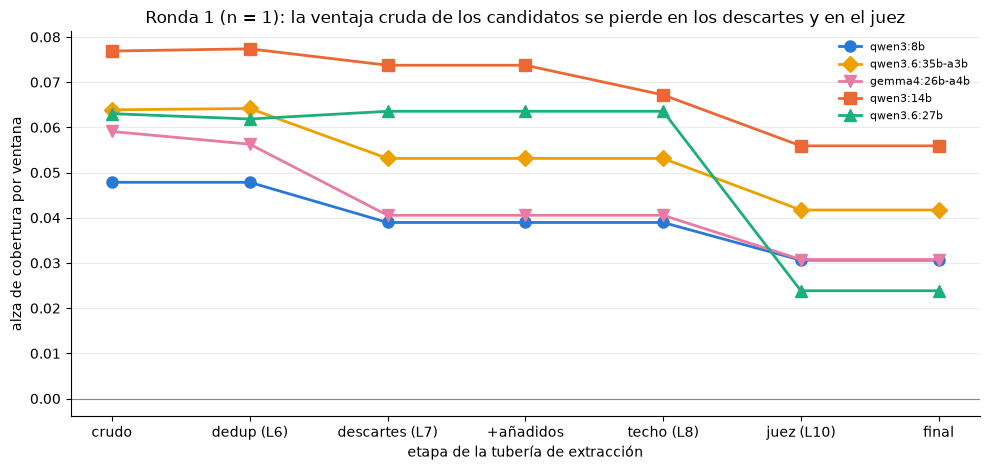

In [7]:
st1 = stage_frame(screens.round1)
fig, ax = plt.subplots(figsize=(10, 4.8))
x = range(len(STAGES))
for model in SCREEN_MODELS:
    d = st1[st1.model == model]
    ax.plot(
        x,
        d.window_lift,
        color=COLORS[model],
        marker=MARKERS[model],
        markersize=8,
        linewidth=2,
        label=model,
    )
ax.set_xticks(list(x), [STAGE_LABELS[s] for s in STAGES])
ax.set_xlim(-0.3, len(STAGES) - 0.7)
ax.axhline(0, color="#888888", linewidth=0.8)
ax.set_ylabel("alza de cobertura por ventana")
ax.set_xlabel("etapa de la tubería de extracción")
ax.set_title(
    "Ronda 1 (n = 1): la ventaja cruda de los candidatos se pierde en los descartes y en el juez"
)
ax.grid(axis="y", alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()

In [8]:
s1 = st1.pivot(index="model", columns="stage", values="window_lift")
raw_base = s1.loc[BASELINE_MODEL, "raw"]
cands = s1.drop(BASELINE_MODEL)
drops = s1["drops"] - s1["dedup"]
judge = s1["judge"] - s1["ceiling"]
w2 = st2.pivot(index="model", columns="stage", values="window_lift")
o = st2.pivot(index="model", columns="stage", values="objects")
display(
    Markdown(
        f"**Resultado — todos los candidatos extraen, en crudo, más oro que `qwen3:8b`, y dos "
        f"etapas se comen esa ventaja.** El alza cruda de los candidatos va de "
        f"{num(cands['raw'].min())} a {num(cands['raw'].max())}, frente a {num(raw_base)} de la "
        "base. "
        f"Los descartes deterministas (L7) quitan {num(drops[BASELINE_MODEL], 4, True)} a "
        "`qwen3:8b`, "
        f"{num(drops['qwen3.6:35b-a3b'], 4, True)} a `qwen3.6:35b-a3b` y "
        f"{num(drops['gemma4:26b-a4b'], 4, True)} "
        "a `gemma4:26b-a4b` (la sección 3 los separa regla por regla). El juez selector (L10) es "
        "la "
        f"pérdida más grande: {num(judge['qwen3.6:27b'], 4, True)} en `qwen3.6:27b` en la ronda "
        "1; en la "
        f"ronda 2 lo lleva de {num(w2.loc['qwen3.6:27b', 'ceiling'])} a "
        f"{num(w2.loc['qwen3.6:27b', 'judge'])} "
        f"y de {o.loc['qwen3.6:27b', 'ceiling']} a {o.loc['qwen3.6:27b', 'judge']} conceptos. "
        "El juez es el mismo modelo que extrae, así que la comparación de modelos queda "
        "confundida "
        "con la de jueces: un extractor más fuerte se juzga a sí mismo. La sección 5 (openkos "
        "#1571) "
        f"lo separa. La señal del atractor de un objeto (L2) también se ve: "
        f"`qwen3:8b` devolvió {o.loc[BASELINE_MODEL, 'raw']} conceptos crudos en "
        f"{r2.set_index('model').loc[BASELINE_MODEL, 'windows']} llamadas de ventana."
    )
)

**Resultado — todos los candidatos extraen, en crudo, más oro que `qwen3:8b`, y dos etapas se comen esa ventaja.** El alza cruda de los candidatos va de 0,0591 a 0,0769, frente a 0,0478 de la base. Los descartes deterministas (L7) quitan -0,0089 a `qwen3:8b`, -0,0110 a `qwen3.6:35b-a3b` y -0,0157 a `gemma4:26b-a4b` (la sección 3 los separa regla por regla). El juez selector (L10) es la pérdida más grande: -0,0397 en `qwen3.6:27b` en la ronda 1; en la ronda 2 lo lleva de 0,0652 a 0,0239 y de 149 a 64 conceptos. El juez es el mismo modelo que extrae, así que la comparación de modelos queda confundida con la de jueces: un extractor más fuerte se juzga a sí mismo. La sección 5 (openkos #1571) lo separa. La señal del atractor de un objeto (L2) también se ve: `qwen3:8b` devolvió 76 conceptos crudos en 82 llamadas de ventana.

### Decisión y salvedades (#1557)

**Decisión.** `qwen3:8b` se queda como modelo de extracción de conceptos. No se cambia ningún
valor por omisión de OpenKOS, y la configuración de C2 en la tesis no se toca
(`generative_model = "qwen3:8b"`).

**Salvedades.**

- **Es un *screen*, no una prueba de que `qwen3:8b` sea el mejor.** Dice que, con esta
  métrica y 5 reuniones, ningún candidato demostró ser mejor. Los IC son anchos.
- **G1 tenía poca potencia con este volumen.** Con unos 70 conceptos etiquetados, el IC de la
  diferencia de precisión mide unos 0,29 de ancho y no puede superar un piso de −0,05 aunque
  el punto esté cerca de 0. El prerregistro de #1558 lo convirtió en reporte y no en veto.
- **La ronda 2 corrió con n = 2 y no con 3**, por la regla de acortamiento registrada (el
  pronóstico superaba 8 h). Lo permitía el prerregistro, pero reduce la potencia.
- **El juez confunde la comparación.** Lo que separa a los candidatos en crudo lo borra el
  juez, y el juez es el mismo modelo. La sección 5 (#1571) lo mide: el acoplamiento es
  significativo solo en `qwen3.6:27b`, justo el candidato que llegó a la ronda 2.
- **Calibración del emparejador de prosa:** el umbral que alcanza precisión 0,96 recupera
  apenas el 10 % de los pares, así que el recall por *embedding* de la prosa casi no difiere
  del exacto. Solo afecta una métrica secundaria.

---

# 3. #1572 — ¿Qué descarte determinista cuesta cobertura?

**Pregunta.** La pérdida L7 de la sección 2.4 junta tres reglas deterministas:
`_drop_framing_objects` (borra conceptos que solo nombran la reunión misma, el
«contenedor»), `_drop_source_title_twins` (gemelos del título de la fuente) y
`_drop_wrong_language_titles` (títulos en otro idioma que la fuente). ¿Cuál causa la
pérdida, y se justifica?

**Por qué importa para la tesis.** Un descarte determinista que borra contenido válido es
una pérdida silenciosa en C2, sin modelo de por medio, y OE4 la atribuiría a la extracción.
Si en cambio lo que borra es ruido («Reunión de diseño del producto»), conservarlo inflaría
la métrica sin agregar conocimiento a la base.

**Método.** Sin ninguna llamada a modelos (`OLLAMA_HOST` apuntado a un puerto cerrado; todos
los *embeddings* ya estaban en caché). Sobre las respuestas crudas guardadas de #1557, se
apaga **una regla a la vez** y se recalcula el alza por ventana: «delta» es alza con la regla
apagada menos alza con todas encendidas (positivo = la regla cuesta alza). IC con el mismo
*bootstrap*. Además, **antes** de calcular ninguna alza, cada concepto descartado se
clasificó a mano desde su tipo, título y descripción como «objetivo» (lo que la regla
pretende borrar) o «falso positivo». Reglas prerregistradas en #1574: una regla es
responsable si apagarla restaura ≥ 50 % de la pérdida L7 en al menos 2 de los 3 modelos que
nombra el *issue*; un falso positivo con delta positivo abre un *issue* de corrección.
Validez: la repetición con todas las reglas encendidas reproduce las etapas grabadas.

In [9]:
rules = drop_rule_frame(screens.ablation, "primary")
display(
    pd.DataFrame(
        {
            "modelo": rules.model,
            "regla": rules.rule,
            "delta [IC 95 %]": [ci(r.delta, r.delta_low, r.delta_high) for r in rules.itertuples()],
            "conceptos descartados": rules.dropped,
            "ventanas que quedan vacías": rules.windows_emptied,
            "falsos positivos": rules.false_positives,
            "delta de los falsos positivos": rules.false_positive_delta.map(
                lambda x: num(x, 4, True)
            ),
        }
    ).set_index(["modelo", "regla"])
)
l7 = l7_attribution(screens.ablation, "primary")
display(
    pd.DataFrame(
        {
            "modelo": l7.model,
            "cambio L7": l7.l7_change.map(lambda x: num(x, 4, True)),
            "parte que restaura framing": l7.framing_share.map(
                lambda x: "— (L7 gana alza)" if pd.isna(x) else pct(x, 0)
            ),
            "cambio L6 (dedup)": l7.dedup_change.map(lambda x: num(x, 4, True)),
            "cortados por el techo (L8)": l7.ceiling_cut,
            "cortados por el tope (L11)": l7.backstop_cut,
            "registros inválidos": l7.invalid_records,
        }
    ).set_index("modelo")
)

delta [IC 95 %]  conceptos descartados  ventanas que quedan vacías  falsos positivos delta de los falsos positivos
modelo          regla                                                                                                                                  
qwen3:8b        dedup     +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
                language  +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
                framing   +0,0089 [-0,0115; +0,0393]                      9                           9                 0                       +0,0000
                twins     +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
qwen3.6:35b-a3b dedup     +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
                language  +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
                framing   +0,0110 [-0,0103; +0,0425]                     21                           8                 0                       +0,0000
                twins     +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
gemma4:26b-a4b  dedup     +0,0030 [+0,0000; +0,0102]                      2                           0                 0                       +0,0000
                language  +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
                framing   +0,0157 [-0,0044; +0,0472]                     20                           5                 0                       +0,0000
                twins     +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
qwen3:14b       dedup     -0,0008 [-0,0024; +0,0000]                      3                           0                 0                       +0,0000
                language  +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
                framing   +0,0036 [-0,0012; +0,0106]                      9                           0                 0                       +0,0000
                twins     +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
qwen3.6:27b     dedup     +0,0012 [+0,0000; +0,0047]                      1                           1                 0                       +0,0000
                language  +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000
                framing   -0,0017 [-0,0126; +0,0118]                     10                           6                 1                       +0,0005
                twins     +0,0000 [+0,0000; +0,0000]                      0                           0                 0                       +0,0000

,cambio L7,parte que restaura framing,cambio L6 (dedup),cortados por el techo (L8),cortados por el tope (L11),registros inválidos
modelo,,,,,,
qwen3:8b,"-0,0089",100 %,"+0,0000",0,0,0
qwen3.6:35b-a3b,"-0,0110",100 %,"+0,0003",0,0,0
gemma4:26b-a4b,"-0,0157",100 %,"-0,0028",0,0,0
qwen3:14b,"-0,0036",100 %,"+0,0005",51,0,0
qwen3.6:27b,"+0,0017",— (L7 gana alza),"-0,0012",0,0,0


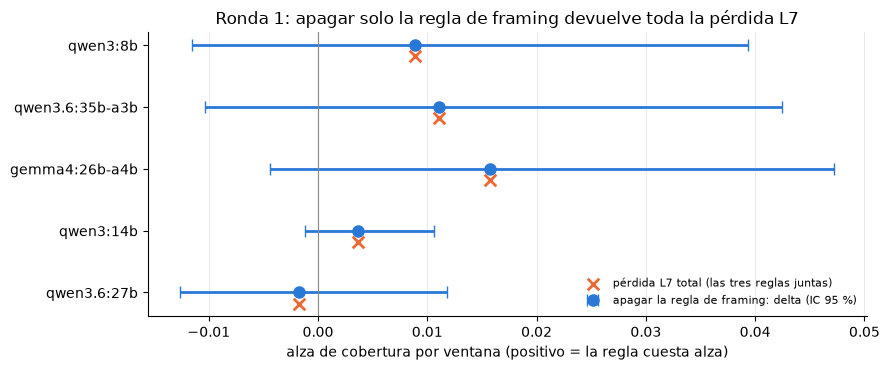

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = list(SCREEN_MODELS)
fr_rules = rules[rules.rule == "framing"].set_index("model").loc[order]
l7i = l7.set_index("model").loc[order]
y = range(len(order))
ax.errorbar(
    fr_rules.delta,
    y,
    xerr=[fr_rules.delta - fr_rules.delta_low, fr_rules.delta_high - fr_rules.delta],
    fmt="o",
    color="#2a78d6",
    ecolor="#2a78d6",
    elinewidth=2,
    capsize=4,
    markersize=8,
    label="apagar la regla de framing: delta (IC 95 %)",
)
ax.scatter(
    -l7i.l7_change,
    [i + 0.18 for i in y],
    marker="x",
    s=70,
    color="#eb6834",
    linewidths=2,
    zorder=3,
    label="pérdida L7 total (las tres reglas juntas)",
)
ax.axvline(0, color="#888888", linewidth=0.8)
ax.set_yticks(list(y), order)
ax.invert_yaxis()
ax.set_xlabel("alza de cobertura por ventana (positivo = la regla cuesta alza)")
ax.set_title("Ronda 1: apagar solo la regla de framing devuelve toda la pérdida L7")
ax.grid(axis="x", alpha=0.25)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

### Auditoría de lo que se descartó

Conteos por regla, clase y tipo sobre los 35 registros (ronda 1 y la corrida 2). Los títulos
y descripciones, que son salida del modelo sobre transcripciones de AMI, no se copiaron a
este repositorio: solo el tipo y la clase asignada.

In [11]:
classes = drop_class_counts(screens.ablation_classes)
display(
    classes.rename(
        columns={"rule": "regla", "class": "clase", "type": "tipo", "objects": "conceptos"}
    ).set_index(["regla", "clase", "tipo"])
)
fp = [r for r in screens.ablation_classes if r["class"] == "false_positive"]
framing = [r for r in screens.ablation_classes if r["rule"] == "framing"]
framing_target = [r for r in framing if r["class"] == "target"]
sec = l7_attribution(screens.ablation, "secondary").set_index("model")
fr8 = fr_rules.loc[BASELINE_MODEL]
named = ("qwen3:8b", "qwen3.6:35b-a3b", "gemma4:26b-a4b")
responsible = sum(l7.set_index("model").loc[m, "framing_share"] >= 0.5 for m in named)
sec_rules = drop_rule_frame(screens.ablation, "secondary").set_index(["model", "rule"])
display(
    Markdown(
        f"**Resultado — la regla de *framing* explica toda la pérdida L7, y lo que borra es casi "
        f"siempre el contenedor.** Apagarla restaura el 100 % de la pérdida en {responsible} de "
        "los "
        f"3 modelos que nombra el *issue* (se exigían 2). Las reglas de gemelos y de idioma "
        f"descartaron 0 conceptos en estas reuniones en inglés. De los {len(framing)} descartes de "
        f"*framing*, {len(framing_target)} son el objetivo (conceptos que nombran la reunión: "
        f"{sum(r['type'] == 'Event' for r in framing_target)} `Event` y "
        f"{sum(r['type'] == 'Project' for r in framing_target)} `Project`) y {len(fp)} es un falso "
        f"positivo: un `{fp[0]['type']}` de `{fp[0]['model']}` en {fp[0]['meeting']}, cuyo título "
        f"menciona la próxima reunión. Su delta es positivo, así que la regla registrada abre un "
        "*issue*: openkos #1575. La mayor parte del costo es el **atractor de un objeto (L2)**: "
        "en "
        f"`qwen3:8b`, los {fr8.dropped} descartes de *framing* de la ronda 1 vaciaron "
        f"{fr8.windows_emptied} ventanas, y en las corridas 1 y 2, "
        f"{sec_rules.loc[(BASELINE_MODEL, 'framing'), 'dropped']} descartes vaciaron "
        f"{sec_rules.loc[(BASELINE_MODEL, 'framing'), 'windows_emptied']}. La ventana había "
        "devuelto "
        f"**solo** el contenedor; al borrarlo queda vacía y puntúa 0."
    )
)

conceptos
regla   clase          tipo               
dedup   target         Project           4
                       Concept           2
framing target         Event            90
                       Project           1
        false_positive Decision          1

**Resultado — la regla de *framing* explica toda la pérdida L7, y lo que borra es casi siempre el contenedor.** Apagarla restaura el 100 % de la pérdida en 3 de los 3 modelos que nombra el *issue* (se exigían 2). Las reglas de gemelos y de idioma descartaron 0 conceptos en estas reuniones en inglés. De los 92 descartes de *framing*, 91 son el objetivo (conceptos que nombran la reunión: 90 `Event` y 1 `Project`) y 1 es un falso positivo: un `Decision` de `qwen3.6:27b` en IS1004b, cuyo título menciona la próxima reunión. Su delta es positivo, así que la regla registrada abre un *issue*: openkos #1575. La mayor parte del costo es el **atractor de un objeto (L2)**: en `qwen3:8b`, los 9 descartes de *framing* de la ronda 1 vaciaron 9 ventanas, y en las corridas 1 y 2, 21 descartes vaciaron 20. La ventana había devuelto **solo** el contenedor; al borrarlo queda vacía y puntúa 0.

### Decisión y salvedades (#1572)

**Decisión.** La regla de *framing* se declara **sana para su clase objetivo** y se mantiene:
el alza que «cuesta» es la métrica premiando la descripción con aire de resumen de un
contenedor de reunión. Devolverlo compraría alza guardando *framing* como si fuera
conocimiento. La palanca está antes: la respuesta de extracción que devolvió solo el
contenedor (L2), no el descarte. El falso positivo queda en openkos #1575: eximir `Decision`
de la regla, o limitarla a tipos contenedor. Esa corrección no está hecha y necesita su propia
medición de falsos positivos. Gemelos e idioma: sanos por ausencia en estos datos. Dedup:
sano, todos sus descartes son duplicados exactos. **No cambia ningún valor por omisión.**

**Salvedades.**

- **Los intervalos de *framing* contienen el 0** en todos los modelos. «Explica toda la
  pérdida L7» es una atribución (la diferencia de conteo en L7 es exactamente la de
  *framing*), no un efecto con IC que excluya el 0.
- **Solo hasta el juez.** Apagar una regla cambia lo que ve el juez selector, y esa respuesta
  nunca se generó. El efecto sobre las etapas juez, final y tope no está medido.
- **Reglas de idioma y gemelos:** que no descarten nada aquí no dice nada de las fuentes en
  español para las que se construyeron.
- **Un solo falso positivo**, en 92 descartes de *framing*. #1575 pide medir la tasa sobre
  más corridas antes de cambiar nada.

---

# 4. #1558 — ¿Qué tamaño de ventana?

**Pregunta.** ¿En cuántos caracteres conviene cortar una fuente antes de extraer
(`_CHUNK_TARGET`, hoy 4.000, sin solape)? Se probaron 6.000, 8.000 y 12.000.

**Por qué importa para la tesis.** Las transcripciones de AMI son largas y el corte decide
cuántas llamadas recibe cada reunión. Con el atractor de un objeto (L2), menos ventanas
podrían significar menos conceptos en la base de C2. Al revés, una ventana más grande parte
menos temas por la mitad (L1). Las dos fuerzas van en sentidos opuestos, y solo midiendo se
sabe cuál pesa más.

**Método.** Mismo oro, misma alza y mismos vetos que #1557, con dos cambios: como otro tamaño
crea otras ventanas, el pareo es **por reunión** (5 reuniones, n = 3) y la primaria es el
**alza por reunión**. Antes de leer ningún brazo, un chequeo de validez (M1) exigía que el
alza por reunión del brazo de 4.000 tuviera un límite inferior > 0 (en #1557 había salido muy
baja a ese nivel). V1 se pondera por caracteres (una ventana de 8.000 fallida pierde el doble)
y se agrega **F**, la tasa de emisiones redundantes (≤ 4.000 + 0,10). Gana el mejor punto con
límite inferior > 0 que cumpla los vetos; si nadie, 4.000 se queda. Modelo primario:
`qwen3:8b`, el único que #1557 dejó para esta etapa. `qwen3.6:27b` se registró como
**exploratorio** (nunca decide), con un presupuesto de 4,0 h de cómputo.

In [12]:
w = window_arm_frame(screens.window)
m1 = screens.window_decision["validity"]["base_meeting_lift"]
print(
    f"M1, alza por reunión del brazo 4.000 (n = 3): {ci(m1['point'], m1['low'], m1['high'])} "
    f"-> {'pasa' if m1['low'] > 0 else 'falla'}"
)
display(
    pd.DataFrame(
        {
            "ventana (caracteres)": w.arm,
            "ventanas por corrida": w.da_windows,
            "dlift reunión [IC 95 %]": [
                "—" if pd.isna(r.dlift) else ci(r.dlift, r.dlift_low, r.dlift_high)
                for r in w.itertuples()
            ],
            "alza reunión": w.meeting_lift.map(num),
            "caracteres fallidos (V1)": w.failed_chars_rate.map(lambda x: num(x, 3)),
            "ventanas fallidas": [f"{r.failed_windows} de {r.window_runs}" for r in w.itertuples()],
            "conceptos/meeting-run (V4)": w.objects_per_meeting.map(lambda x: num(x, 2)),
            "redundantes (F)": w.redundant_rate.map(lambda x: num(x, 3)),
            "cobertura juzgada": w.judge_coverage.map(lambda x: num(x, 3)),
            "G1 precisión": w.g1_precision.map(lambda x: num(x, 3)),
            "medium-10 recall exacto": w.medium10_recall.map(lambda x: num(x, 3)),
            "s/meeting-run": w.s_per_meeting_run.map(lambda x: num(x, 1)),
        }
    ).set_index("ventana (caracteres)")
)
print("Delta por reunión (brazo menos 4.000, media de 3 corridas):")
display(per_meeting_deltas(screens.window).round(4))

M1, alza por reunión del brazo 4.000 (n = 3): +0,0098 [+0,0031; +0,0174] -> pasa


,ventanas por corrida,dlift reunión [IC 95 %],alza reunión,caracteres fallidos (V1),ventanas fallidas,conceptos/meeting-run (V4),redundantes (F),cobertura juzgada,G1 precisión,medium-10 recall exacto,s/meeting-run
ventana (caracteres),,,,,,,,,,,
4000,41,—,"0,0098","0,022",3 de 123,"4,60","0,130","0,255","0,933","0,667","307,0"
6000,27,"-0,0044 [-0,0124; +0,0036]","0,0054","0,013",3 de 81,"2,93","0,045","0,221","0,893","0,727","272,8"
8000,22,"-0,0143 [-0,0237; -0,0064]","-0,0045","0,000",0 de 66,"2,40","0,083","0,205","0,923","0,576","263,7"
12000,15,"-0,0036 [-0,0095; +0,0039]","0,0062","0,047",2 de 45,"2,20","0,061","0,129","0,941","0,364","332,0"


Delta por reunión (brazo menos 4.000, media de 3 corridas):


meeting,ES2015a,ES2015d,IS1004b,IS1004d,TS3009c
arm,,,,,
6000,-0.0130,0.0084,0.0020,-0.0166,-0.0030
8000,-0.0034,-0.0109,-0.0184,-0.0071,-0.0317
12000,-0.0128,-0.0038,-0.0051,-0.0065,0.0104


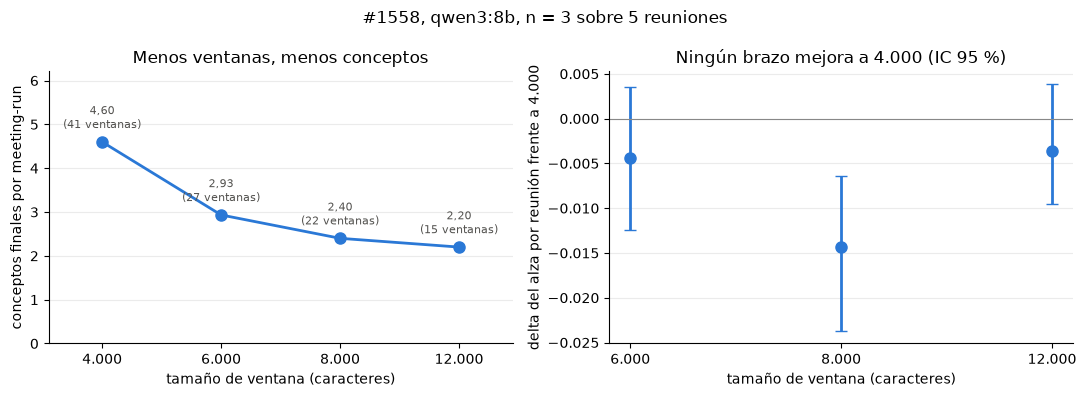

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
labels = [f"{a:,}".replace(",", ".") for a in w.arm]
ax1.plot(labels, w.objects_per_meeting, color="#2a78d6", marker="o", markersize=8, linewidth=2)
for lab, v, n in zip(labels, w.objects_per_meeting, w.da_windows, strict=True):
    ax1.annotate(
        f"{num(v, 2)}\n({n} ventanas)",
        (lab, v),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="#52514e",
    )
ax1.set_ylim(0, w.objects_per_meeting.max() * 1.35)
ax1.margins(x=0.15)
ax1.set_ylabel("conceptos finales por meeting-run")
ax1.set_xlabel("tamaño de ventana (caracteres)")
ax1.set_title("Menos ventanas, menos conceptos")
d = w[w.arm != 4000]
dl = [f"{a:,}".replace(",", ".") for a in d.arm]
ax2.errorbar(
    dl,
    d.dlift,
    yerr=[d.dlift - d.dlift_low, d.dlift_high - d.dlift],
    fmt="o",
    color="#2a78d6",
    elinewidth=2,
    capsize=4,
    markersize=8,
)
ax2.axhline(0, color="#888888", linewidth=0.8)
ax2.set_ylabel("delta del alza por reunión frente a 4.000")
ax2.set_xlabel("tamaño de ventana (caracteres)")
ax2.set_title("Ningún brazo mejora a 4.000 (IC 95 %)")
for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle("#1558, qwen3:8b, n = 3 sobre 5 reuniones")
fig.tight_layout()
plt.show()

### Regla de selección, reaplicada

In [14]:
wsel = window_selection(w)
display(wsel.drop(columns="volume"))
display(trace_frame(screens.window_decision, key="arm"))
harness = {t["arm"]: t["passed"] for t in screens.window_decision["trace"]}
assert dict(zip(wsel.arm, wsel.selected, strict=True)) == harness
assert screens.window_decision["winner"] is None

# The registered forecast for the exploratory model (PREREGISTRATION, "Procedure and budget"):
# D and P are #1557's DA and medium-10 seconds per run for qwen3.6:27b, fixed in the
# registration; t_4000 is its #1557 stage-0 median.
REGISTERED_D_27B, REGISTERED_P_27B = 2927, 446
forecast = exploratory_forecast(
    screens.window_stage0,
    model="qwen3.6:27b",
    da_seconds=REGISTERED_D_27B,
    medium10_seconds=REGISTERED_P_27B,
    median_4000_s=screens.model_stage0["models"]["qwen3.6:27b"]["median_window_s"],
    da_windows=dict(zip(w.arm, w.da_windows, strict=True)),
    medium10_windows=dict(zip(w.arm, w.medium10_windows, strict=True)),
)
d_measured = screens.round2["models"]["qwen3.6:27b"]["total_s"] / len(screens.round2["runs"])
display(
    pd.DataFrame(
        [
            {
                "trabajo": f"{a:,}".replace(",", ".") + " caracteres, dos corridas",
                "segundos": round(s),
            }
            for a, s in forecast.per_arm_s.items()
        ]
        + [
            {"trabajo": "medium-10, semilla 2, a 4.000", "segundos": round(forecast.medium10_s)},
            {"trabajo": "stage 0 ya gastado", "segundos": round(forecast.stage0_s)},
            {"trabajo": "total", "segundos": round(forecast.total_s)},
        ]
    ).set_index("trabajo")
)
print(
    f"D registrado {REGISTERED_D_27B} s; medido en #1557 (ronda 2, por corrida): {d_measured:.0f} s"
)

base = w.set_index("arm").loc[4000]
a12 = w.set_index("arm").loc[12000]
a8 = w.set_index("arm").loc[8000]
display(
    Markdown(
        f"**Resultado — no hay ganador: 4.000 se queda.** M1 pasó, así que el alza por reunión "
        f"fue la primaria. Ningún brazo tiene un límite inferior > 0: 6.000 y 12.000 tienen "
        f"intervalos que cruzan el 0 con punto negativo, y 8.000 es **peor** con un IC que excluye "
        f"el 0 ({ci(a8.dlift, a8.dlift_low, a8.dlift_high)}). 12.000 además falla V1 "
        f"({num(a12.failed_chars_rate, 3)} de caracteres fallidos frente a "
        f"{num(base.failed_chars_rate, 3)} + 0,02) y V4 ({num(a12.objects_per_meeting, 2)} "
        "conceptos, "
        f"bajo el piso de {num(0.5 * base.objects_per_meeting, 2)}). El mecanismo es el atractor "
        "de "
        f"un objeto: los conceptos por meeting-run caen de {num(base.objects_per_meeting, 2)} a "
        f"{', '.join(num(v, 2) for v in w.objects_per_meeting.iloc[1:])} al pasar de "
        f"{', '.join(str(v) for v in w.da_windows)} ventanas. La cobertura cae con ellos (juzgada: "
        f"de {num(base.judge_coverage, 3)} a {num(a12.judge_coverage, 3)}), y la precisión no sube "
        f"para compensar (G1 entre {num(w.g1_precision.min(), 2)} y "
        f"{num(w.g1_precision.max(), 2)}). "
        "La fragmentación que una ventana mayor podría arreglar es real pero chica: 4.000 tiene "
        "la "
        f"mayor tasa de redundantes ({num(base.redundant_rate, 3)}), y lo que se pierde en "
        "cobertura "
        f"pesa más. El modelo exploratorio `qwen3.6:27b` **no se corrió**: el pronóstico con la "
        f"fórmula registrada da {f'{round(forecast.total_s):,}'.replace(',', '.')} s = "
        f"{num(forecast.total_s / 3600, 2)} h, "
        f"sobre el presupuesto de {num(forecast.budget_s / 3600, 1)} h."
    )
)

,arm,lift lower > 0,V1,V3,V4,V5,F,selected
0,6000,False,True,True,True,True,True,False
1,8000,False,True,True,True,True,True,False
2,12000,False,False,True,False,True,True,False


,arm,passed,reasons
0,6000,False,dlift lower bound -0.0124 <= 0
1,8000,False,dlift lower bound -0.0237 <= 0
2,12000,False,"V1 failed chars 21059 of 451338 (0.047) > 4,000 arm 0.022 + 0.02; V4 volume 2.20 outsi..."


,segundos
trabajo,
"6.000 caracteres, dos corridas",7935
"8.000 caracteres, dos corridas",5637
"medium-10, semilla 2, a 4.000",446
stage 0 ya gastado,521
total,14540


D registrado 2927 s; medido en #1557 (ronda 2, por corrida): 2927 s


**Resultado — no hay ganador: 4.000 se queda.** M1 pasó, así que el alza por reunión fue la primaria. Ningún brazo tiene un límite inferior > 0: 6.000 y 12.000 tienen intervalos que cruzan el 0 con punto negativo, y 8.000 es **peor** con un IC que excluye el 0 (-0,0143 [-0,0237; -0,0064]). 12.000 además falla V1 (0,047 de caracteres fallidos frente a 0,022 + 0,02) y V4 (2,20 conceptos, bajo el piso de 2,30). El mecanismo es el atractor de un objeto: los conceptos por meeting-run caen de 4,60 a 2,93, 2,40, 2,20 al pasar de 41, 27, 22, 15 ventanas. La cobertura cae con ellos (juzgada: de 0,255 a 0,129), y la precisión no sube para compensar (G1 entre 0,89 y 0,94). La fragmentación que una ventana mayor podría arreglar es real pero chica: 4.000 tiene la mayor tasa de redundantes (0,130), y lo que se pierde en cobertura pesa más. El modelo exploratorio `qwen3.6:27b` **no se corrió**: el pronóstico con la fórmula registrada da 14.540 s = 4,04 h, sobre el presupuesto de 4,0 h.

### Decisión y salvedades (#1558)

**Decisión.** `_CHUNK_TARGET` se queda en 4.000 caracteres. No se escribe ADR en OpenKOS y no
cambia ningún valor por omisión. Para la tesis, C2 sigue construyéndose con la ventana por
omisión.

**Salvedades.**

- **Los IC son gruesos.** Descansan en 5 reuniones: el *screen* puede decir que ninguna
  ventana mayor ayuda a `qwen3:8b`, pero no puede ordenar 6.000 frente a 12.000.
- **Solo un modelo.** El atractor de un objeto se midió en `qwen3:8b`. La pregunta de si un
  modelo más grande aprovecha mejor una ventana mayor quedó abierta: `qwen3.6:27b` se saltó
  por la regla del presupuesto, por un margen de unos 2 minutos sobre 4 h. Es la regla
  operando, no evidencia en contra.
- **Las fugas de la captura de participantes** (llamadas que llegan al tope de generación)
  aparecen en todos los brazos, incluido 4.000. No las causa el tamaño de ventana.
- **8.000 pierde más en los descartes** (su alza por reunión se vuelve negativa en la etapa
  de descartes). Es evidencia de un solo brazo, no un mecanismo medido.

In [15]:
ws = window_stage_frame(screens.window)
display(
    ws.assign(etapa=ws.stage.map(STAGE_LABELS), alza=ws.meeting_lift.map(num))
    .pivot(index="arm", columns="etapa", values="alza")[[STAGE_LABELS[s] for s in STAGES]]
    .rename_axis("ventana")
)

etapa,crudo,dedup (L6),descartes (L7),+añadidos,techo (L8),juez (L10),final
ventana,,,,,,,
4000,"0,0136","0,0140","0,0114","0,0117","0,0117","0,0098","0,0098"
6000,"0,0138","0,0136","0,0149","0,0107","0,0107","0,0054","0,0054"
8000,"0,0076","0,0061","-0,0042","-0,0041","-0,0041","-0,0045","-0,0045"
12000,"0,0036","0,0034","0,0046","0,0074","0,0074","0,0062","0,0062"


---

# 5. #1571 — ¿La pérdida del juez es el juez, o que el extractor se juzgue a sí mismo?

**Pregunta.** El juez selector (L10) fue la mayor pérdida por etapa en la sección 2.4. Pero en
producción el juez es **el mismo modelo que extrae**, así que la puntuación final de un
modelo mezcla qué tan bien extrae con qué tan bien se juzga a sí mismo. ¿Cuánto de la pérdida
es la selección en sí, y cuánto es ese acoplamiento? ¿Es el juez el filtro correcto?

**Por qué importa para la tesis.** El juez decide qué conceptos llegan a la base de C2. Si la
pérdida fuera del acoplamiento, cambiar el modelo del juez sería una mejora barata para C2
antes de abrir las series de evaluación. Si es la selección misma, cambiar de juez no la
arregla, y una pérdida de C2 frente a C1 se atribuye (OE4) a una etapa de filtrado que existe
a propósito: compra precisión a costa de cobertura.

**Método.** Sobre las respuestas crudas guardadas de #1557 (ronda 1, 5 *meeting-runs* por
extractor; las de la ronda 2 como secundario), se vuelve a correr **solo el juez**, en tres
brazos con la misma entrada (la etapa `ceiling` grabada):

- **sin juez** (`none`): lo que entra al juez;
- **juez propio** (`self`): el mismo extractor; la semilla 0 es la llamada grabada en #1557
  y las semillas 1 y 2 son llamadas nuevas;
- **juez fijo** (`fixed`): `gemma4:26b-a4b`, el `DEFAULT_JUDGE_MODEL` de OpenKOS, con tres
  semillas nuevas.

Cada extracción salió de la caché de #1557 (0 fallos de caché). La «pérdida» de un brazo es su
alza por ventana menos la de `none`, con el mismo *bootstrap* pareado. El **acoplamiento** es
`fixed` menos `self`: positivo significa que el juez fijo conserva más alza que el propio.
`gemma4:26b-a4b` como extractor tiene el mismo modelo en los dos brazos, así que no se
compara. Regla prerregistrada (#1578), por extractor: **acoplamiento** si el límite inferior
del acoplamiento es > 0; si no, **juez** si el límite superior de la pérdida con juez fijo es
< 0; si no, **sin resolver**. Veredicto global: «acoplamiento» con 2 o más; «el juez» con 2 o
más y ningún acoplamiento; si no, «sin resolver con este n». La precisión (G1) quedó fuera de
alcance por registro.

In [16]:
js = judge_study_frame(screens.judge_study, "primary")
jsi = js.set_index("model")
r1_judge = stage_frame(screens.round1).set_index(["model", "stage"]).window_lift
replayed = {m: jsi.loc[m, "self_seed_lifts"][0] for m in jsi.index}
# Equal up to floating-point summation order (the two harnesses add in different orders).
gap_judge = max(abs(replayed[m] - r1_judge[(m, "judge")]) for m in replayed)
gap_input = max(abs(jsi.loc[m, "none_lift"] - r1_judge[(m, "ceiling")]) for m in replayed)
assert gap_judge < 1e-8 and gap_input < 1e-8, "el estudio no reproduce las etapas de #1557"
print(
    "Validez: sin juez reproduce la etapa ceiling y la semilla 0 del juez propio la etapa "
    f"juez de #1557 en los {len(replayed)} extractores (diferencia máxima "
    f"{max(gap_judge, gap_input):.1e}, orden de suma)."
)


def judge_table(frame):
    return pd.DataFrame(
        {
            "extractor": frame.model,
            "sin juez: alza (conceptos)": [
                f"{num(r.none_lift)} ({r.none_kept:.0f})" for r in frame.itertuples()
            ],
            "propio: alza (conservados)": [
                f"{num(r.self_lift)} ({num(r.self_kept, 1)})" for r in frame.itertuples()
            ],
            "fijo: alza (conservados)": [
                f"{num(r.fixed_lift)} ({num(r.fixed_kept, 1)})" for r in frame.itertuples()
            ],
            "pérdida propio [IC 95 %]": [
                ci(r.self_loss, r.self_loss_low, r.self_loss_high) for r in frame.itertuples()
            ],
            "pérdida fijo [IC 95 %]": [
                ci(r.fixed_loss, r.fixed_loss_low, r.fixed_loss_high) for r in frame.itertuples()
            ],
            "acoplamiento [IC 95 %]": [
                "— (mismo modelo)"
                if r.model == FIXED_JUDGE
                else ci(r.coupling, r.coupling_low, r.coupling_high)
                for r in frame.itertuples()
            ],
        }
    ).set_index("extractor")


display(judge_table(js))
print("Alza por ventana por semilla (propio s0/s1/s2 | fijo s0/s1/s2):")
display(
    pd.DataFrame(
        {
            "extractor": js.model,
            "propio": [" / ".join(num(v) for v in r.self_seed_lifts) for r in js.itertuples()],
            "fijo": [" / ".join(num(v) for v in r.fixed_seed_lifts) for r in js.itertuples()],
            "fallas del juez": (js.self_failed + js.fixed_failed),
        }
    ).set_index("extractor")
)
print("Secundario, corridas 1 y 2 (solo se reporta):")
display(judge_table(judge_study_frame(screens.judge_study, "secondary")))

Validez: sin juez reproduce la etapa ceiling y la semilla 0 del juez propio la etapa juez de #1557 en los 5 extractores (diferencia máxima 3.7e-10, orden de suma).


,sin juez: alza (conceptos),propio: alza (conservados),fijo: alza (conservados),pérdida propio [IC 95 %],pérdida fijo [IC 95 %],acoplamiento [IC 95 %]
extractor,,,,,,
qwen3:8b,"0,0390 (31)","0,0274 (25,3)","0,0186 (20,0)","-0,0116 [-0,0284; +0,0000]","-0,0203 [-0,0417; -0,0028]","-0,0088 [-0,0198; -0,0001]"
qwen3.6:35b-a3b,"0,0531 (58)","0,0395 (31,7)","0,0456 (36,7)","-0,0136 [-0,0241; -0,0024]","-0,0076 [-0,0198; +0,0038]","+0,0060 [-0,0044; +0,0177]"
gemma4:26b-a4b,"0,0405 (86)","0,0317 (56,0)","0,0317 (56,0)","-0,0089 [-0,0265; +0,0033]","-0,0089 [-0,0265; +0,0033]",— (mismo modelo)
qwen3:14b,"0,0672 (112)","0,0576 (71,3)","0,0503 (53,3)","-0,0095 [-0,0429; +0,0057]","-0,0169 [-0,0395; -0,0012]","-0,0073 [-0,0206; +0,0087]"
qwen3.6:27b,"0,0636 (65)","0,0261 (29,3)","0,0408 (34,7)","-0,0374 [-0,0693; -0,0148]","-0,0228 [-0,0412; -0,0067]","+0,0146 [+0,0018; +0,0369]"


Alza por ventana por semilla (propio s0/s1/s2 | fijo s0/s1/s2):


,propio,fijo,fallas del juez
extractor,,,
qwen3:8b,"0,0306 / 0,0258 / 0,0258","0,0186 / 0,0192 / 0,0180",0
qwen3.6:35b-a3b,"0,0417 / 0,0368 / 0,0401","0,0457 / 0,0452 / 0,0457",0
gemma4:26b-a4b,"0,0308 / 0,0298 / 0,0346","0,0308 / 0,0298 / 0,0346",0
qwen3:14b,"0,0559 / 0,0570 / 0,0600","0,0607 / 0,0446 / 0,0456",0
qwen3.6:27b,"0,0238 / 0,0265 / 0,0281","0,0443 / 0,0374 / 0,0406",0


Secundario, corridas 1 y 2 (solo se reporta):


,sin juez: alza (conceptos),propio: alza (conservados),fijo: alza (conservados),pérdida propio [IC 95 %],pérdida fijo [IC 95 %],acoplamiento [IC 95 %]
extractor,,,,,,
qwen3:8b,"0,0357 (63)","0,0275 (47,0)","0,0231 (39,3)","-0,0082 [-0,0208; -0,0000]","-0,0125 [-0,0255; -0,0012]","-0,0044 [-0,0160; +0,0107]"
qwen3.6:27b,"0,0652 (149)","0,0273 (70,3)","0,0447 (83,3)","-0,0380 [-0,0659; -0,0154]","-0,0205 [-0,0395; -0,0033]","+0,0175 [+0,0058; +0,0408]"


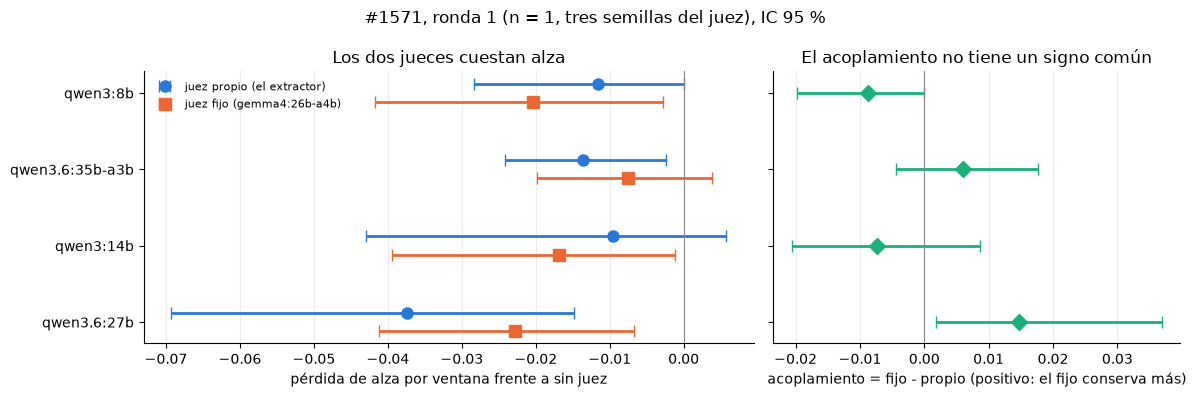

In [17]:
order = [m for m in SCREEN_MODELS if m != FIXED_JUDGE]
d = jsi.loc[order]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True, width_ratios=(3, 2))
y = list(range(len(order)))
for arm, color, marker, shift, label in (
    ("self", "#2a78d6", "o", -0.12, "juez propio (el extractor)"),
    ("fixed", "#eb6834", "s", 0.12, "juez fijo (gemma4:26b-a4b)"),
):
    ax1.errorbar(
        d[f"{arm}_loss"],
        [i + shift for i in y],
        xerr=[d[f"{arm}_loss"] - d[f"{arm}_loss_low"], d[f"{arm}_loss_high"] - d[f"{arm}_loss"]],
        fmt=marker,
        color=color,
        elinewidth=2,
        capsize=4,
        markersize=8,
        label=label,
    )
ax1.axvline(0, color="#888888", linewidth=0.8)
ax1.set_yticks(y, order)
ax1.invert_yaxis()
ax1.set_xlabel("pérdida de alza por ventana frente a sin juez")
ax1.set_title("Los dos jueces cuestan alza")
ax1.legend(frameon=False, fontsize=8, loc="upper left")
ax2.errorbar(
    d.coupling,
    y,
    xerr=[d.coupling - d.coupling_low, d.coupling_high - d.coupling],
    fmt="D",
    color="#1baf7a",
    elinewidth=2,
    capsize=4,
    markersize=8,
)
ax2.axvline(0, color="#888888", linewidth=0.8)
ax2.set_xlabel("acoplamiento = fijo - propio (positivo: el fijo conserva más)")
ax2.set_title("El acoplamiento no tiene un signo común")
for ax in (ax1, ax2):
    ax.grid(axis="x", alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle("#1571, ronda 1 (n = 1, tres semillas del juez), IC 95 %")
fig.tight_layout()
plt.show()

### Regla prerregistrada, reaplicada

In [18]:
labels = judge_labels(js)
verdict, follow_up = judge_verdict(labels)
harness = screens.judge_study["decision"]
assert labels == harness["labels"] and verdict == harness["verdict"]
assert follow_up == harness["follow_up"]
LABELS_ES = {"coupling": "acoplamiento", "judge": "juez", "unresolved": "sin resolver"}
VERDICT_ES = {
    "coupling": "el acoplamiento",
    "judge": "el juez en sí",
    "not_resolved": "sin resolver con este n",
}
display(
    pd.DataFrame(
        [
            {
                "extractor": m,
                "acoplamiento inf. > 0": jsi.loc[m, "coupling_low"] > 0,
                "pérdida fija sup. < 0": jsi.loc[m, "fixed_loss_high"] < 0,
                "etiqueta": LABELS_ES[label],
            }
            for m, label in labels.items()
        ]
    ).set_index("extractor")
)
j27, j8 = jsi.loc["qwen3.6:27b"], jsi.loc["qwen3:8b"]
recovered = j27.coupling / -j27.self_loss
n_fixed_excl = int((js[js.model != FIXED_JUDGE].fixed_loss_high < 0).sum())
s8 = j8.self_seed_lifts
display(
    Markdown(
        f"**Resultado — sin resolver por la regla registrada; la selección misma cuesta alza y el "
        f"acoplamiento importa solo en `qwen3.6:27b`.** La regla reaplicada coincide con el arnés: "
        f"{', '.join(f'`{m}` {LABELS_ES[v]}' for m, v in labels.items())}. Veredicto global: "
        f"**{VERDICT_ES[verdict]}**, porque hay extractores de los dos tipos (la etiqueta «juez» "
        f"exige que ninguno sea «acoplamiento»). El juez fijo sigue costando alza en todos los "
        f"extractores, y su intervalo excluye el 0 en {n_fixed_excl} de "
        f"{len(js) - 1}: cambiar el modelo del juez no elimina la pérdida. En `qwen3.6:27b` el "
        f"acoplamiento es real: su propio juez lo lleva de {num(j27.none_lift)} a "
        f"{num(j27.self_lift)}, el fijo a {num(j27.fixed_lift)} "
        f"(acoplamiento {ci(j27.coupling, j27.coupling_low, j27.coupling_high)}), y recupera "
        f"{pct(recovered, 0)} de la pérdida. En `qwen3:8b`, el modelo de producción, pasa lo "
        f"contrario: el juez fijo corta **más** que el propio "
        f"({ci(j8.coupling, j8.coupling_low, j8.coupling_high)}). Además, la cifra grabada en "
        "#1557 "
        f"para `qwen3:8b` fue su mejor semilla: {num(s8[0])} en la semilla 0 frente a "
        f"{num(s8[1])} y {num(s8[2])} en las otras dos. Como hay extractores atribuibles, la regla "
        f"pide un *issue* de corrección: openkos #1579. No cambia nada por omisión."
    )
)

,acoplamiento inf. > 0,pérdida fija sup. < 0,etiqueta
extractor,,,
qwen3:8b,False,True,juez
qwen3.6:35b-a3b,False,False,sin resolver
qwen3:14b,False,True,juez
qwen3.6:27b,True,True,acoplamiento


**Resultado — sin resolver por la regla registrada; la selección misma cuesta alza y el acoplamiento importa solo en `qwen3.6:27b`.** La regla reaplicada coincide con el arnés: `qwen3:8b` juez, `qwen3.6:35b-a3b` sin resolver, `qwen3:14b` juez, `qwen3.6:27b` acoplamiento. Veredicto global: **sin resolver con este n**, porque hay extractores de los dos tipos (la etiqueta «juez» exige que ninguno sea «acoplamiento»). El juez fijo sigue costando alza en todos los extractores, y su intervalo excluye el 0 en 3 de 4: cambiar el modelo del juez no elimina la pérdida. En `qwen3.6:27b` el acoplamiento es real: su propio juez lo lleva de 0,0636 a 0,0261, el fijo a 0,0408 (acoplamiento +0,0146 [+0,0018; +0,0369]), y recupera 39 % de la pérdida. En `qwen3:8b`, el modelo de producción, pasa lo contrario: el juez fijo corta **más** que el propio (-0,0088 [-0,0198; -0,0001]). Además, la cifra grabada en #1557 para `qwen3:8b` fue su mejor semilla: 0,0306 en la semilla 0 frente a 0,0258 y 0,0258 en las otras dos. Como hay extractores atribuibles, la regla pide un *issue* de corrección: openkos #1579. No cambia nada por omisión.

### Decisión y salvedades (#1571)

**Decisión.** El veredicto prerregistrado es **sin resolver con este n**. El juez selector se
mantiene tal cual, con el mismo modelo que extrae, y ningún valor por omisión cambia. La
propuesta de corrección (por ejemplo, un modelo fijo para el juez, o cambiar la selección)
quedó en openkos #1579, sin hacer: tiene que pesar también la precisión. Para la tesis, C2 se
construye con `qwen3:8b` juzgándose a sí mismo, que es justo el caso en que un juez fijo
**empeora** la cobertura.

**Salvedades.**

- **La cobertura no es calidad.** El juez existe para comprar precisión, y G1 no se volvió a
  medir (fuera de alcance por registro). Un corte puede bajar el alza y estar bien hecho, por
  ejemplo con un concepto vago que parafrasea el resumen de la reunión o un casi duplicado.
- **n pequeño.** Una corrida de extracción, 5 *meeting-runs* por extractor y tres semillas del
  juez. Los intervalos son anchos, y por eso dos extractores quedan cerca del borde (el
  acoplamiento de `qwen3:8b` excluye el 0 por 0,0001).
- **Un solo juez fijo.** `gemma4:26b-a4b` es el juez por omisión que OpenKOS ya trae. Otro
  modelo fijo podría dar otro patrón.
- **El acoplamiento cambia la lectura de #1557.** La alza final de `qwen3.6:27b` en el
  *screen* cargaba el costo de su propio juez. Si alguna vez se adopta un extractor más fuerte,
  no se puede suponer que el juez se traslade con él.

---

# 6. #1560 — ¿Qué modelo responde, verifica la suficiencia y cita?

**Pregunta.** La consulta (*Ask*) de OpenKOS usa el modelo en tres papeles: la
**verificación de suficiencia** (`_context_holds_the_answer`: ¿el contexto recuperado alcanza
para responder?; si no, se abstiene), la **respuesta** y la **citación** (la línea `USED:` que
cierra la respuesta). Los tres siguen hoy al modelo global, `qwen3:8b`. ¿Algún modelo local
lo hace mejor en alguno, también con preguntas en español sobre una base en inglés?

**Por qué importa para la tesis (C2).** C2 y C3 responden con `openkos query` (ADR 0006).
Si la verificación de suficiencia **rechaza una pregunta que sí tiene respuesta** en el
contexto, C2 se abstiene y pierde ese punto aunque la base y la recuperación estuvieran bien:
un error que OE4 atribuiría a la síntesis y no a la extracción. Las preguntas de la tesis
son en español sobre transcripciones de AMI en inglés, el caso cruzado que este *screen*
mide. Y como la tesis exige el mismo modelo de respuesta en C1, C2 y C3 (§5.3), el resultado
de la respuesta es insumo directo de mcd-afg #143.

**Método.** Solo documentos **sintéticos** del repositorio de OpenKOS: ningún material de AMI
ni serie de la tesis. Las mismas 32 preguntas en español sobre tres bases (96 ítems por
corrida): `es-es` (14 documentos en español), `es-en` (su espejo en inglés) y `es-built` (una
base compilada por `openkos ingest` desde tres transcripciones sintéticas en inglés). De las
32, 20 tienen etiqueta de respondible o no (10 y 10) y 12 tienen hechos de oro para la
respuesta. Métrica por papel: suficiencia, veredicto correcto; respuesta, parte de los hechos
de oro que la respuesta enuncia (solo las 12 anclas); citación, `USED:` correcto. El
estadístico es el **delta pareado** frente a `qwen3:8b`, agrupado sobre las tres bases, con
*bootstrap* de 10.000 remuestreos. Vetos: **V1** fallas, **V2** latencia (≤ 2,0 × base),
**S1** rechazos de preguntas respondibles (≤ base), **S2** preguntas no respondibles dadas
por respondibles (≤ base + 0,02), **V3** respuestas en español (≥ base − 0,05), **V4**
cumplimiento de `USED:` (≥ base − 0,05), **X1** pérdida clara en `es-en`, y **M** memoria
(≤ 24 GB). Procedimiento: *stage 0* (latencia y memoria; `qwen3.6:27b` cayó ahí por V2 en
las dos llamadas), ronda 1 con *successive halving*, ronda 2 (n = 2 por la regla de
acortamiento registrada) con selección (mejor punto con límite inferior > 0 y sin vetos), y
una **confirmación con 5 semillas nuevas** (11 a 15), porque el ganador de un *screen* trae
sesgo de selección. Prerregistro fusionado en openkos #1582 antes de la primera llamada
puntuada.

In [19]:
ask = screens.ask_rounds
ROLE_ES = {"sufficiency": "suficiencia", "answer": "respuesta", "citation": "citación"}
ROUND_ES = {
    "round1": "ronda 1 (n = 1)",
    "round2": "ronda 2 (n = 2)",
    "confirmation": "confirmación (n = 5)",
}
frames = []
for rnd, report in ask.items():
    for role in ASK_ROLES:
        f = ask_role_frame(report, role)
        if f.empty:
            continue
        assert (f.vetoes == f.harness_vetoes).all(), "vetos reaplicados distintos del arnés"
        kept = ask_halving(f) if rnd == "round1" else set()
        selected = None if rnd == "round1" else ask_select(f)
        assert rnd == "round1" or selected == report["roles"][role]["selected"]
        assert rnd != "round1" or kept == set(report["roles"][role]["kept"])
        frames.append(
            f.assign(round=rnd, role=role, kept=f.model.isin(kept), selected=f.model == selected)
        )
ask_frame = pd.concat(frames, ignore_index=True)
display(
    pd.DataFrame(
        {
            "fase": ask_frame["round"].map(ROUND_ES),
            "papel": ask_frame.role.map(ROLE_ES),
            "candidato": ask_frame.model,
            "base (media)": ask_frame.baseline_mean.map(lambda x: num(x, 3)),
            "delta [IC 95 %]": [
                ci(r.delta, r.delta_low, r.delta_high, 3) for r in ask_frame.itertuples()
            ],
            "es-es": ask_frame["es-es"].map(lambda x: num(x, 3, True)),
            "es-en": ask_frame["es-en"].map(lambda x: num(x, 3, True)),
            "es-built": ask_frame["es-built"].map(lambda x: num(x, 3, True)),
            "vetos": ask_frame.vetoes.map(lambda v: ", ".join(v) or "—"),
            "resultado": [
                "seleccionado"
                if r.selected
                else ("sigue" if r.kept else ("—" if r.round != "round1" else "cae"))
                for r in ask_frame.itertuples()
            ],
        }
    ).set_index(["fase", "papel", "candidato"])
)
print("Vetos y selección reaplicados: coinciden con el arnés en todas las fases y papeles.")
ask_g1 = ask["round1"]["guardrails"]
conf_g = ask["confirmation"]["guardrails"]
display(
    pd.DataFrame(
        [
            {
                "fase": ROUND_ES[rnd],
                "modelo": m,
                "s mediana suficiencia": num(g["suff_median_s"], 2),
                "rechazos indebidos (S1)": num(g["grounded_refused"], 3),
                "no respondibles aceptadas (S2)": num(g["adjacent_missed"], 3),
                "respuestas en español (V3)": "—"
                if rnd == "confirmation"
                else num(g["spanish_answers"], 3),
                "cumplimiento USED: (V4)": "—"
                if rnd == "confirmation"
                else num(g["compliance"], 3),
            }
            for rnd in ("round1", "confirmation")
            for m, g in ask[rnd]["guardrails"].items()
        ]
    ).set_index(["fase", "modelo"])
)
print("La confirmación solo hizo la llamada de suficiencia: sus columnas V3 y V4 no se midieron.")

base (media)          delta [IC 95 %]   es-es   es-en es-built vetos     resultado
fase                 papel       candidato                                                                                         
ronda 1 (n = 1)      suficiencia gemma4:26b-a4b         0,854  +0,062 [+0,000; +0,125]  +0,031  +0,062   +0,094     —         sigue
                                 qwen3:14b              0,854  +0,073 [+0,021; +0,125]  +0,031  +0,094   +0,094     —         sigue
                                 qwen3.6:35b-a3b        0,854  +0,052 [-0,010; +0,115]  +0,031  +0,062   +0,062    S2           cae
                     respuesta   gemma4:26b-a4b         0,833  +0,000 [-0,111; +0,111]  +0,083  +0,083   -0,167    V3           cae
                                 qwen3:14b              0,833  -0,083 [-0,222; +0,056]  +0,000  +0,083   -0,333    V3           cae
                                 qwen3.6:35b-a3b        0,833  +0,000 [-0,139; +0,139]  +0,000  +0,083   -0,083    V3           cae
                     citación    gemma4:26b-a4b         0,865  +0,052 [-0,010; +0,125]  +0,125  +0,031   +0,000     —         sigue
                                 qwen3:14b              0,865  +0,031 [-0,042; +0,104]  +0,094  +0,000   +0,000     —         sigue
                                 qwen3.6:35b-a3b        0,865  +0,010 [-0,062; +0,083]  +0,125  +0,000   -0,094     —           cae
ronda 2 (n = 2)      suficiencia gemma4:26b-a4b         0,839  +0,078 [+0,021; +0,141]  +0,062  +0,078   +0,094     —  seleccionado
                                 qwen3:14b              0,839  +0,078 [+0,031; +0,130]  +0,062  +0,078   +0,094     —             —
                     respuesta   gemma4:26b-a4b         0,833  +0,000 [-0,083; +0,083]  +0,083  +0,042   -0,125    V3             —
                                 qwen3:14b              0,833  -0,097 [-0,222; +0,014]  +0,000  +0,000   -0,292    V3             —
                     citación    gemma4:26b-a4b         0,865  +0,042 [-0,026; +0,115]  +0,109  +0,016   +0,000     —             —
                                 qwen3:14b              0,865  +0,016 [-0,047; +0,078]  +0,047  +0,016   -0,016     —             —
confirmación (n = 5) suficiencia gemma4:26b-a4b         0,821  +0,096 [+0,035; +0,163]  +0,100  +0,094   +0,094     —  seleccionado

Vetos y selección reaplicados: coinciden con el arnés en todas las fases y papeles.


s mediana suficiencia rechazos indebidos (S1) no respondibles aceptadas (S2) respuestas en español (V3) cumplimiento USED: (V4)
fase                 modelo                                                                                                                                         
ronda 1 (n = 1)      qwen3:8b                         2,72                   0,212                          0,000                      0,917                   1,000
                     gemma4:26b-a4b                   1,90                   0,121                          0,000                      0,781                   0,979
                     qwen3:14b                        4,94                   0,106                          0,000                      0,771                   1,000
                     qwen3.6:35b-a3b                  2,05                   0,106                          0,067                      0,771                   0,958
confirmación (n = 5) qwen3:8b                         1,93                   0,261                          0,000                          —                       —
                     gemma4:26b-a4b                   1,88                   0,121                          0,000                          —                       —

La confirmación solo hizo la llamada de suficiencia: sus columnas V3 y V4 no se midieron.


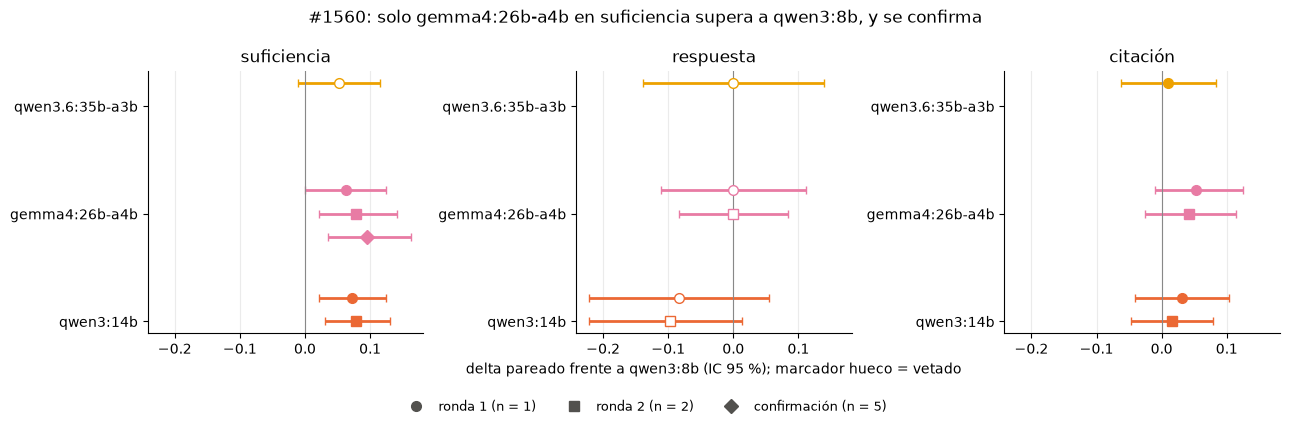

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True)
ROUND_STYLE = {"round1": ("o", 0.0), "round2": ("s", 0.22), "confirmation": ("D", 0.44)}
for ax, role in zip(axes, ASK_ROLES, strict=True):
    sub = ask_frame[ask_frame.role == role]
    models = [m for m in SCREEN_MODELS if m in set(sub.model)]
    for rnd, (marker, shift) in ROUND_STYLE.items():
        part = sub[sub["round"] == rnd].set_index("model")
        for i, m in enumerate(models):
            if m not in part.index:
                continue
            r = part.loc[m]
            vetoed = len(r.vetoes) > 0
            ax.errorbar(
                r.delta,
                i + shift,
                xerr=[[r.delta - r.delta_low], [r.delta_high - r.delta]],
                fmt=marker,
                color=COLORS[m],
                elinewidth=2,
                capsize=3,
                markersize=7,
                markerfacecolor="white" if vetoed else COLORS[m],
                label=ROUND_ES[rnd] if i == 0 else None,
            )
    ax.axvline(0, color="#888888", linewidth=0.8)
    ax.set_yticks([i + 0.22 for i in range(len(models))], models)
    ax.invert_yaxis()
    ax.set_title(ROLE_ES[role])
    ax.grid(axis="x", alpha=0.25)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[1].set_xlabel("delta pareado frente a qwen3:8b (IC 95 %); marcador hueco = vetado")
handles = [
    plt.Line2D([], [], marker=mk, color="#52514e", linestyle="none", markersize=7)
    for mk, _ in ROUND_STYLE.values()
]
fig.legend(
    handles,
    [ROUND_ES[k] for k in ROUND_STYLE],
    loc="lower center",
    ncol=3,
    frameon=False,
    fontsize=9,
)
fig.suptitle("#1560: solo gemma4:26b-a4b en suficiencia supera a qwen3:8b, y se confirma")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

In [21]:
pens = []
for rnd in ("round2", "confirmation"):
    pens.append(ask_penalty_frame(ask[rnd]).assign(fase=ROUND_ES[rnd]))
pen = pd.concat(pens, ignore_index=True)
display(
    pd.DataFrame(
        {
            "fase": pen.fase,
            "modelo": pen.model,
            "papel": pen.role.map(ROLE_ES),
            "penalización es-en menos es-es [IC 95 %]": [
                ci(r.penalty, r.low, r.high, 3) for r in pen.itertuples()
            ],
        }
    ).set_index(["fase", "modelo", "papel"])
)
pen_conf = pen[pen.fase == ROUND_ES["confirmation"]].set_index("model")
ask_r2s = ask_frame[(ask_frame["round"] == "round2") & (ask_frame.role == "sufficiency")].set_index(
    "model"
)
conf_row = ask_frame[ask_frame["round"] == "confirmation"].set_index("model").loc["gemma4:26b-a4b"]
ask_selected = {
    role: ask["confirmation"]["roles"][role]["selected"] or ask["round2"]["roles"][role]["selected"]
    for role in ASK_ROLES
}
max_abs_pen = pen[pen.model == BASELINE_MODEL].penalty.abs().max()
pen_rows_base = pen[pen.model == BASELINE_MODEL]
all_include_zero = bool(((pen_rows_base.low <= 0) & (pen_rows_base.high >= 0)).all())
zero_text = "todos sus intervalos contienen" if all_include_zero else "no todos contienen"
display(
    Markdown(
        f"**Resultado — `gemma4:26b-a4b` gana la verificación de suficiencia y se confirma; la "
        f"respuesta y la citación se quedan en `qwen3:8b`.** En la ronda 2, `gemma4:26b-a4b` y "
        "`qwen3:14b` empatan exacto en suficiencia "
        f"({num(ask_r2s.loc['gemma4:26b-a4b', 'delta'], 6, True)} "
        f"los dos); la regla registrada desempata por nombre y elige `gemma4:26b-a4b` (que además "
        f"es más rápido en esa llamada). En la confirmación, con 5 semillas nuevas, su delta es "
        f"{ci(conf_row.delta, conf_row.delta_low, conf_row.delta_high, 3)} sobre {conf_row.n} "
        "ítems, "
        f"sin vetos, y la ganancia es pareja en las tres bases ({num(conf_row['es-es'], 3, True)}, "
        f"{num(conf_row['es-en'], 3, True)}, {num(conf_row['es-built'], 3, True)}). Viene de "
        f"**rechazar menos preguntas que sí tienen respuesta**: "
        f"{num(conf_g['gemma4:26b-a4b']['grounded_refused'], 3)} frente a "
        f"{num(conf_g['qwen3:8b']['grounded_refused'], 3)}, sin aceptar ninguna sin respuesta "
        f"({num(conf_g['gemma4:26b-a4b']['adjacent_missed'], 3)}). En **respuesta**, todos los "
        f"candidatos cayeron por V3 (respuestas en español: base "
        f"{num(ask_g1[BASELINE_MODEL]['spanish_answers'], 3)}, `gemma4:26b-a4b` "
        f"{num(ask_g1['gemma4:26b-a4b']['spanish_answers'], 3)}). En **citación**, ningún límite "
        f"inferior superó el 0. La **penalización entre idiomas** de `qwen3:8b` (`es-en` menos "
        f"`es-es`) no pasa de {num(max_abs_pen, 3)} en valor absoluto en ningún papel, y "
        f"{zero_text} el 0: "
        f"preguntar en español sobre una base en inglés no le cuesta nada medible."
    )
)

penalización es-en menos es-es [IC 95 %]
fase                 modelo         papel                                               
ronda 2 (n = 2)      qwen3:8b       suficiencia                  -0,016 [-0,109; +0,062]
                                    respuesta                    +0,042 [+0,000; +0,125]
                                    citación                     +0,031 [+0,000; +0,078]
                     gemma4:26b-a4b suficiencia                  +0,000 [+0,000; +0,000]
                                    respuesta                    +0,000 [+0,000; +0,000]
                                    citación                     -0,062 [-0,141; +0,000]
                     qwen3:14b      suficiencia                  +0,000 [-0,047; +0,047]
                                    respuesta                    +0,042 [-0,125; +0,250]
                                    citación                     +0,000 [-0,078; +0,062]
confirmación (n = 5) qwen3:8b       suficiencia                  +0,006 [-0,081; +0,094]
                     gemma4:26b-a4b suficiencia                  +0,000 [+0,000; +0,000]

**Resultado — `gemma4:26b-a4b` gana la verificación de suficiencia y se confirma; la respuesta y la citación se quedan en `qwen3:8b`.** En la ronda 2, `gemma4:26b-a4b` y `qwen3:14b` empatan exacto en suficiencia (+0,078125 los dos); la regla registrada desempata por nombre y elige `gemma4:26b-a4b` (que además es más rápido en esa llamada). En la confirmación, con 5 semillas nuevas, su delta es +0,096 [+0,035; +0,163] sobre 96 ítems, sin vetos, y la ganancia es pareja en las tres bases (+0,100, +0,094, +0,094). Viene de **rechazar menos preguntas que sí tienen respuesta**: 0,121 frente a 0,261, sin aceptar ninguna sin respuesta (0,000). En **respuesta**, todos los candidatos cayeron por V3 (respuestas en español: base 0,917, `gemma4:26b-a4b` 0,781). En **citación**, ningún límite inferior superó el 0. La **penalización entre idiomas** de `qwen3:8b` (`es-en` menos `es-es`) no pasa de 0,042 en valor absoluto en ningún papel, y todos sus intervalos contienen el 0: preguntar en español sobre una base en inglés no le cuesta nada medible.

**Por qué V3 vetó a todos los candidatos de respuesta.** V3 cuenta el idioma de **todas** las
respuestas, incluidas las de preguntas sin respuesta en el contexto. Según `RESULTS.md` (la
cuenta se hizo sobre el texto de las respuestas, que no se copió a este repositorio), en las
preguntas respondibles los candidatos responden en español tanto o más que la base, pero en
las 30 no respondibles no: el *prompt* de respuesta (`answer/system.md`) trae una frase de
rechazo de ejemplo **en inglés** («the compiled bundle does not cover this»), y todas las
respuestas no españolas de `gemma4:26b-a4b` (21 de 21) y de `qwen3:14b` (16 de 16) la citan
textual, mientras `qwen3:8b` la parafrasea en español. El veto mide tanto un defecto del
*prompt* como al modelo, pero es la regla registrada y se mantiene. El *prompt* se corrige en
openkos #1583, y luego se vuelve a medir la respuesta.

### Decisión y salvedades (#1560)

**Decisión.**

- **Suficiencia: `gemma4:26b-a4b`, seleccionado y confirmado, pero NO adoptado.** La
  adopción va en un PR aparte con su propio ADR y una clave de tarea nueva, como exige el
  registro: openkos PR #1585 (ADR-0076, *Proposed*), **sin fusionar**. Queda pendiente de
  medir el costo de cambiar de modelo en cada consulta (sección 9). Hasta entonces, OpenKOS
  sigue verificando con `qwen3:8b`.
- **Respuesta y citación: se queda `qwen3:8b`.** Para la tesis, en este *screen* nada
  desplaza a `qwen3:8b` como modelo de respuesta común a C1, C2 y C3 (insumo de mcd-afg #143).

**Salvedades.**

- **Bases chicas y sintéticas.** 14 documentos cortos y una base compilada de tres
  transcripciones; las cifras ordenan modelos en este tipo de pregunta, no son calidad
  absoluta. `es-built` es más débil para todos los modelos (su extracción dejó 14 objetos, 10
  de ellos `Person`), pero igual para todos, así que el pareo se sostiene.
- **La respuesta se mide por hechos con nombre**, no por la calidad de la prosa.
- **Preguntas en inglés: no se midieron** (openkos #1581).
- **V2 midió latencia en caliente.** El costo de cargar un segundo modelo en cada consulta
  no está medido; es justo lo que retiene #1585.
- **No usa AMI.** El *screen* no dice nada directo sobre las transcripciones de la tesis; la
  penalización entre idiomas ≈ 0 es la mejor evidencia disponible para el caso español sobre
  inglés, pero sobre documentos sintéticos.

---

# 7. Cotejo con los informes de OpenKOS

**Qué se hace y por qué.** Las cifras de arriba se calculan desde los archivos de puntaje. Aquí
se comparan con las que publican `RESULTS.md` (#1557 y #1558) y `DROP_ABLATION_RESULTS.md`
(#1572), `JUDGE_STUDY_RESULTS.md` (#1571) y `evals/ask_model_screen/RESULTS.md` (#1560), transcritas a mano con el redondeo con que aparecen, para detectar cualquier
diferencia entre el informe y sus datos.

In [22]:
r1i, r2i, wi = r1.set_index("model"), r2.set_index("model"), w.set_index("arm")
st1i = st1.set_index(["model", "stage"]).window_lift
l7i = l7.set_index("model")
published = [
    # (what, published value, computed value, decimals)
    ("#1557 validez: alza de la base", 0.0306, base_ci["point"], 4),
    ("#1557 r1 dlift qwen3:14b", 0.0253, r1i.loc["qwen3:14b", "dlift"], 4),
    ("#1557 r1 dlift qwen3.6:27b", -0.0068, r1i.loc["qwen3.6:27b", "dlift"], 4),
    (
        "#1557 r1 conceptos/meeting-run gemma4",
        11.40,
        r1i.loc["gemma4:26b-a4b", "objects_per_meeting"],
        2,
    ),
    ("#1557 r2 dlift qwen3.6:27b", -0.0079, r2i.loc["qwen3.6:27b", "dlift"], 4),
    ("#1557 r2 dlift límite inferior", -0.0423, r2i.loc["qwen3.6:27b", "dlift_low"], 4),
    ("#1557 r2 G1 límite inferior", -0.1739, g.loc["qwen3.6:27b", "dprecision_low"], 4),
    (
        "#1559 r1 L7 qwen3:8b (titular)",
        -0.0088,
        st1i[("qwen3:8b", "drops")] - st1i[("qwen3:8b", "dedup")],
        4,
    ),
    (
        "#1559 r1 L7 qwen3.6:35b-a3b (titular)",
        -0.0111,
        st1i[("qwen3.6:35b-a3b", "drops")] - st1i[("qwen3.6:35b-a3b", "dedup")],
        4,
    ),
    (
        "#1559 r1 L7 gemma4 (titular)",
        -0.0158,
        st1i[("gemma4:26b-a4b", "drops")] - st1i[("gemma4:26b-a4b", "dedup")],
        4,
    ),
    (
        "#1559 r1 juez qwen3.6:27b (titular)",
        -0.0398,
        st1i[("qwen3.6:27b", "judge")] - st1i[("qwen3.6:27b", "ceiling")],
        4,
    ),
    (
        "#1559 r2 juez qwen3.6:27b (tabla)",
        -0.0413,
        w2.loc["qwen3.6:27b", "judge"] - w2.loc["qwen3.6:27b", "ceiling"],
        4,
    ),
    ("#1572 L7 qwen3:8b", -0.0089, l7i.loc["qwen3:8b", "l7_change"], 4),
    ("#1572 L7 gemma4", -0.0157, l7i.loc["gemma4:26b-a4b", "l7_change"], 4),
    ("#1572 framing qwen3.6:27b", -0.0017, fr_rules.loc["qwen3.6:27b", "delta"], 4),
    ("#1558 M1", 0.0098, m1["point"], 4),
    ("#1558 dlift 8.000", -0.0143, wi.loc[8000, "dlift"], 4),
    ("#1558 dlift 8.000 límite superior", -0.0064, wi.loc[8000, "dlift_high"], 4),
    ("#1558 V1 12.000", 0.047, wi.loc[12000, "failed_chars_rate"], 3),
    ("#1558 conceptos 12.000", 2.20, wi.loc[12000, "objects_per_meeting"], 2),
    ("#1558 pronóstico 27b (s)", 14528, forecast.total_s, 0),
    ("#1558 pronóstico 27b (h)", 4.04, forecast.total_s / 3600, 2),
    ("#1571 qwen3.6:27b sin juez", 0.0636, jsi.loc["qwen3.6:27b", "none_lift"], 4),
    ("#1571 qwen3.6:27b juez propio", 0.0261, jsi.loc["qwen3.6:27b", "self_lift"], 4),
    ("#1571 qwen3.6:27b juez fijo", 0.0408, jsi.loc["qwen3.6:27b", "fixed_lift"], 4),
    ("#1571 acoplamiento qwen3.6:27b", 0.0146, jsi.loc["qwen3.6:27b", "coupling"], 4),
    ("#1571 acoplamiento qwen3.6:27b inf.", 0.0018, jsi.loc["qwen3.6:27b", "coupling_low"], 4),
    ("#1571 acoplamiento qwen3:8b", -0.0088, jsi.loc["qwen3:8b", "coupling"], 4),
    ("#1571 acoplamiento qwen3:8b sup.", -0.0001, jsi.loc["qwen3:8b", "coupling_high"], 4),
    ("#1571 pérdida fija qwen3:8b", -0.0203, jsi.loc["qwen3:8b", "fixed_loss"], 4),
    ("#1571 pérdida fija qwen3:8b sup.", -0.0028, jsi.loc["qwen3:8b", "fixed_loss_high"], 4),
    ("#1571 pérdida fija qwen3:14b sup.", -0.0012, jsi.loc["qwen3:14b", "fixed_loss_high"], 4),
    ("#1571 parte recuperada qwen3.6:27b", 0.39, recovered, 2),
    ("#1560 r1 S2 qwen3.6:35b-a3b", 0.067, ask_g1["qwen3.6:35b-a3b"]["adjacent_missed"], 3),
    ("#1560 r1 V3 base", 0.917, ask_g1["qwen3:8b"]["spanish_answers"], 3),
    ("#1560 r1 V3 gemma4", 0.781, ask_g1["gemma4:26b-a4b"]["spanish_answers"], 3),
    ("#1560 r2 suficiencia gemma4", 0.078, ask_r2s.loc["gemma4:26b-a4b", "delta"], 3),
    ("#1560 r2 suficiencia qwen3:14b", 0.078, ask_r2s.loc["qwen3:14b", "delta"], 3),
    ("#1560 confirmación delta", 0.096, conf_row.delta, 3),
    ("#1560 confirmación inf.", 0.035, conf_row.delta_low, 3),
    ("#1560 confirmación sup.", 0.163, conf_row.delta_high, 3),
    ("#1560 rechazos indebidos gemma4", 0.121, conf_g["gemma4:26b-a4b"]["grounded_refused"], 3),
    ("#1560 rechazos indebidos qwen3:8b", 0.261, conf_g["qwen3:8b"]["grounded_refused"], 3),
    ("#1560 penalización qwen3:8b (conf.)", 0.006, pen_conf.loc["qwen3:8b", "penalty"], 3),
]
# "Matches" means equal at the published rounding: within half a unit of its last digit.
check = pd.DataFrame(
    [
        {
            "cifra": n,
            "publicada": p,
            "calculada": round(c, d + 2),
            "coincide": abs(c - p) <= 0.5 * 10**-d + 1e-12,
        }
        for n, p, c, d in published
    ]
)
display(check)
display(check[~check.coincide])

,cifra,publicada,calculada,coincide
0,#1557 validez: alza de la base,0.0306,0.030608,True
1,#1557 r1 dlift qwen3:14b,0.0253,0.025297,True
2,#1557 r1 dlift qwen3.6:27b,-0.0068,-0.006759,True
3,#1557 r1 conceptos/meeting-run gemma4,11.4000,11.400000,True
4,#1557 r2 dlift qwen3.6:27b,-0.0079,-0.007943,True
5,#1557 r2 dlift límite inferior,-0.0423,-0.042251,True
6,#1557 r2 G1 límite inferior,-0.1739,-0.173913,True
7,#1559 r1 L7 qwen3:8b (titular),-0.0088,-0.008889,False
8,#1559 r1 L7 qwen3.6:35b-a3b (titular),-0.0111,-0.011048,False
9,#1559 r1 L7 gemma4 (titular),-0.0158,-0.015730,False


,cifra,publicada,calculada,coincide
7,#1559 r1 L7 qwen3:8b (titular),-0.0088,-0.008889,False
8,#1559 r1 L7 qwen3.6:35b-a3b (titular),-0.0111,-0.011048,False
9,#1559 r1 L7 gemma4 (titular),-0.0158,-0.015730,False
10,#1559 r1 juez qwen3.6:27b (titular),-0.0398,-0.039707,False
20,#1558 pronóstico 27b (s),14528.0000,14539.720000,False


**Lectura de las diferencias.** Ninguna cambia un veredicto, y todas vienen del redondeo:

- **Las pérdidas del titular de #1559** (L7: −0,0088, −0,0111 y −0,0158; juez en
  `qwen3.6:27b`: −0,0398, en `RESULTS.md`) restan las alzas ya redondeadas de la tabla por
  etapa (por ejemplo 0,0478 → 0,0390). Calculadas sin redondear dan −0,0089, −0,0110,
  −0,0157 y −0,0397. Las de L7 son las que publica `DROP_ABLATION_RESULTS.md`, que ya lo
  señala («matches the published table to rounding»).
- **#1560:** nada difiere más allá del redondeo. El límite superior de la confirmación es
  exactamente 0,1625, que `RESULTS.md` publica como 0,163 (redondeo hacia arriba en el
  medio); por eso la comparación se hace a medio dígito y no con `round`.
- **El pronóstico del modelo exploratorio** publicado (14.528 s) usa las medianas de *stage 0*
  redondeadas a un decimal (93,6 s, 83,8 s y 53,4 s); con las medianas sin redondear da unos
  12 s más. Las horas (4,04 h) y la decisión (supera las 4,0 h) no cambian.

---

# 8. Decisiones vigentes

**Qué se hace y por qué.** Se resume, en una tabla generada desde los archivos de decisión, qué
queda fijado para la extracción de conceptos con que se construye C2.

In [23]:
winner_1557 = screens.model_decisions["r2-2"]["winner"] or "ninguno"
winner_1558 = screens.window_decision["winner"] or "ninguno"
verdict_1571 = VERDICT_ES[screens.judge_study["decision"]["verdict"]]
follow_1571 = "sí" if screens.judge_study["decision"]["follow_up"] else "no"
decisions = pd.DataFrame(
    [
        {
            "issue OpenKOS": "#1557",
            "pregunta": "modelo de extracción de conceptos",
            "veredicto del arnés": f"ganador: {winner_1557}",
            "decisión vigente": f"se queda {', '.join(screens.model_decisions['r2-2']['top_two'])}",
            "evidencia clave": (
                f"r2: dlift {ci(c.dlift, c.dlift_low, c.dlift_high)}; G1 inf. "
                f"{num(g.loc['qwen3.6:27b', 'dprecision_low'], 4, True)} < -0,05"
            ),
        },
        {
            "issue OpenKOS": "#1559",
            "pregunta": "pérdida por etapa",
            "veredicto del arnés": "medición, sin regla de decisión",
            "decisión vigente": (
                "el juez (L10) y los descartes (L7) son las pérdidas grandes; "
                "cada una abre su issue"
            ),
            "evidencia clave": (
                f"juez en qwen3.6:27b r2: {num(w2.loc['qwen3.6:27b', 'ceiling'])} → "
                f"{num(w2.loc['qwen3.6:27b', 'judge'])} ({o.loc['qwen3.6:27b', 'ceiling']} → "
                f"{o.loc['qwen3.6:27b', 'judge']} conceptos)"
            ),
        },
        {
            "issue OpenKOS": "#1572",
            "pregunta": "qué descarte cuesta alza",
            "veredicto del arnés": "framing es la responsable",
            "decisión vigente": (
                "framing se mantiene (sana para el contenedor); falso positivo en #1575"
            ),
            "evidencia clave": (
                f"restaura el 100 % de L7 en {responsible} de 3; "
                f"{len(framing_target)} de {len(framing)} descartes son el objetivo"
            ),
        },
        {
            "issue OpenKOS": "#1571",
            "pregunta": "pérdida del juez selector: juez o acoplamiento",
            "veredicto del arnés": f"{verdict_1571}; seguimiento: {follow_1571}",
            "decisión vigente": (
                "el juez se mantiene; no cambia nada por omisión; propuesta en openkos #1579"
            ),
            "evidencia clave": (
                f"acoplamiento solo en qwen3.6:27b "
                f"({ci(j27.coupling, j27.coupling_low, j27.coupling_high)}); "
                f"el juez fijo corta más en qwen3:8b "
                f"({ci(j8.coupling, j8.coupling_low, j8.coupling_high)})"
            ),
        },
        {
            "issue OpenKOS": "#1560",
            "pregunta": "modelos de Ask: suficiencia, respuesta y citación",
            "veredicto del arnés": (
                f"suficiencia: {ask_selected['sufficiency']} (confirmado); "
                f"respuesta y citación: ninguno"
            ),
            "decisión vigente": (
                "suficiencia: adopción de gemma4:26b-a4b PENDIENTE (PR openkos #1585, sin "
                "fusionar); respuesta y citación: se queda qwen3:8b"
            ),
            "evidencia clave": (
                f"confirmación {ci(conf_row.delta, conf_row.delta_low, conf_row.delta_high, 3)}; "
                f"rechazos indebidos {num(conf_g['gemma4:26b-a4b']['grounded_refused'], 3)} "
                f"frente a {num(conf_g['qwen3:8b']['grounded_refused'], 3)}"
            ),
        },
        {
            "issue OpenKOS": "#1558",
            "pregunta": "tamaño de ventana",
            "veredicto del arnés": f"ganador: {winner_1558}",
            "decisión vigente": "_CHUNK_TARGET se queda en 4.000",
            "evidencia clave": (
                f"8.000: {ci(a8.dlift, a8.dlift_low, a8.dlift_high)}; "
                f"27b no corrió ({num(forecast.total_s / 3600, 2)} h > 4,0 h)"
            ),
        },
    ]
).set_index("issue OpenKOS")
decisions

,pregunta,veredicto del arnés,decisión vigente,evidencia clave
issue OpenKOS,,,,
#1557,modelo de extracción de conceptos,ganador: ninguno,se queda qwen3:8b,"r2: dlift -0,0079 [-0,0423; +0,0196]; G1 inf. -0,1739 < -0,05"
#1559,pérdida por etapa,"medición, sin regla de decisión",el juez (L10) y los descartes (L7) son las pérdidas grandes; cada una abre su issue,"juez en qwen3.6:27b r2: 0,0652 → 0,0239 (149 → 64 conceptos)"
#1572,qué descarte cuesta alza,framing es la responsable,framing se mantiene (sana para el contenedor); falso positivo en #1575,restaura el 100 % de L7 en 3 de 3; 91 de 92 descartes son el objetivo
#1571,pérdida del juez selector: juez o acoplamiento,sin resolver con este n; seguimiento: sí,el juez se mantiene; no cambia nada por omisión; propuesta en openkos #1579,"acoplamiento solo en qwen3.6:27b (+0,0146 [+0,0018; +0,0369]); el juez fijo corta más ..."
#1560,"modelos de Ask: suficiencia, respuesta y citación",suficiencia: gemma4:26b-a4b (confirmado); respuesta y citación: ninguno,"suficiencia: adopción de gemma4:26b-a4b PENDIENTE (PR openkos #1585, sin fusionar); re...","confirmación +0,096 [+0,035; +0,163]; rechazos indebidos 0,121 frente a 0,261"
#1558,tamaño de ventana,ganador: ninguno,_CHUNK_TARGET se queda en 4.000,"8.000: -0,0143 [-0,0237; -0,0064]; 27b no corrió (4,04 h > 4,0 h)"


Ninguna de las seis cambia, hoy, un valor por omisión de OpenKOS: la única adopción
propuesta (la verificación de suficiencia con `gemma4:26b-a4b`) está pendiente. Para la tesis, la
consecuencia es que **C2 se construye con la configuración de extracción por omisión**
(`qwen3:8b`, ventanas de 4.000 caracteres, las reglas de descarte actuales), y que ahora hay
evidencia prerregistrada, sobre series de desarrollo, de que ningún cambio probado la
mejoraba. Las pérdidas grandes que quedan (el juez selector y el atractor de un objeto) son
de la tubería y no del modelo ni de la ventana. Con `qwen3:8b` el juez propio corta menos que
un juez fijo, así que tampoco hay un cambio de juez que la tesis debiera pedir para C2. Si C2
pierde contenido frente a C1, OE4 tiene dónde buscarlo. Del lado de la respuesta, nada desplaza
a `qwen3:8b` como modelo que redacta y cita, que es el que la tesis exige común a C1, C2 y C3
(§5.3).

---

# 9. Pendiente

- **openkos PR #1585 — verificación del cambio de modelo.** Propone `gemma4:26b-a4b` para la
  verificación de suficiencia (ADR-0076, *Proposed*) y **no está fusionado**. Con un solo
  modelo residente (el piso de 32 GB del ADR-0047), cada consulta en frío cargaría
  `gemma4:26b-a4b` para la verificación y luego `qwen3:8b` para redactar: un cambio de modelo
  por consulta cuyo costo el *screen* no midió (su veto V2 midió latencia en caliente). Hasta
  que se mida y se fusione, la verificación sigue en `qwen3:8b`.
- **mcd-afg #143 — el modelo de C2 y el modelo común (§5.3).** Sigue abierto: decidir el
  alcance de «mismo modelo generativo», el modelo de extracción de C2 y C3 y el de respuesta,
  registrarlo en un ADR y actualizar `config/experiments.toml`. Este notebook es su insumo del
  lado de OpenKOS. Si se adopta #1585, además hay que decidir si la copia de `sufficiency.md`
  que usa C1 (ADR 0006) cambia de modelo con C2 y C3, para no romper la paridad.
- **mcd-afg #141 y #142** (referencia en inglés y umbral τ) ya están cerrados: el
  [notebook 17](17-jss-tau-referencia-en.ipynb) y el ADR 0012 los resolvieron.